# TT2 · Detección y Mitigación de Calibration Drift — Diabetes 130-US Hospitals
**Trabajo Terminal 2026-B080 · ESCOM-IPN** · Casas Aguilar José David · Robles Cervantes Pedro Iván

Notebook final de código (fase TT2) para el dataset *Diabetes 130-US Hospitals 1999–2008* (`diabetic_data.csv` + `IDS_mapping.csv`, UCI 296). Se ejecuta de punta a punta en Google Colab y deja exportados el modelo, el pipeline de preprocesamiento y las tablas que consumirá el dashboard.

**Qué corrige respecto de TT1**

| Problema detectado en TT1 | Corrección en TT2 | Sección |
|---|---|---|
| Pesos de clase (`scale_pos_weight` = 9.1, `balanced`) → ECE ≈ 0.33–0.40 ya en calibración | Modelos sin ponderación + ablación que lo demuestra | 3.6 |
| Lectura de `IDS_mapping.csv` rota: solo se cargó 1 de 3 tablas y `admission_type` quedó con textos de `admission_source` | Parser robusto (CSV con CRLF, 3 tablas) y verificación contra la lectura ingenua | 1.6 |
| `pandas` convirtió el valor "None" de HbA1c y glucosa en NaN | Lectura con `keep_default_na=False`: "None" = *no medido*, categoría explícita | 1.5 |
| IDs administrativos tratados como números y recortados | Traducidos con `IDS_mapping` a categorías; códigos "NULL / Not Mapped / Not Available" → *Desconocido* | 2.3 |
| Vocabularios y top-10 de especialidades calculados con todo el dataset (fuga) | Vocabularios congelados con train | 2.3 |
| 148 columnas one-hot (23 medicamentos por separado) | Medicamentos agregados, ICD-9 en 9 grupos, edad ordinal | 2.3, 2.5 |
| Últimos encuentros con etiqueta **censurada** (readmisiones posteriores a la extracción no registradas) | Diagnóstico de madurez de la etiqueta y exclusión de la cola | 1.7 |
| Recalibración evaluada *in-sample*; reentrenamiento con 7 000 filas | Evaluación prequential con retraso de etiquetas; el enfoque TT1 queda como "oráculo" | 4.6 |
| Umbrales PSI fijos y monitor saturado | Umbrales empíricos (distribución nula) + señal de calibración | 2.6, 4.6 |
| Latencia y falsas alarmas "N/A" | Validación del monitor con escenarios de verdad conocida | 4.7 |
| Sin tiempos de procesamiento | Registro por etapa, repeticiones y hardware | 1.2, 3.5, 5.5 |

**Observaciones del jurado → dónde se atienden**
1. Tiempos de procesamiento → registro `TIMINGS`, `%%time` en entrenamiento, §3.5 y §5.5
2. Justificación de modelos → §3.1 y evidencia empírica §3.6–3.7
3. Explicación de los datos sin tecnicismos → ficha en lenguaje llano §1.5
4. Requisitos de un dataset candidato → validador `validate_dataset()` §1.8
5. Maquetado del dashboard → contrato de artefactos y mapeo a vistas §5.4
6. Análisis estático vs ajuste de dimensionalidad → §2.5

## 1. Configuración y carga
### 1.1 Instalación de dependencias
Colab ya incluye pandas, NumPy, SciPy y matplotlib; aquí se aseguran versiones mínimas de las librerías críticas. XGBoost ≥ 2.0 es necesario por el soporte nativo de variables categóricas.

In [1]:
%pip install -q "xgboost>=2.0" "scikit-learn>=1.3" "pyarrow>=14" psutil joblib

### 1.2 Importaciones, configuración central, registro de tiempos y entorno
- Toda decisión paramétrica vive en `CONFIG` (trazabilidad).
- `timed()` registra duración y memoria de cada etapa en `TIMINGS`; la tabla se exporta para el dashboard (**observación 1**).
- `ENV` documenta el hardware y las versiones.

In [2]:
import os, sys, io, re, json, time, hashlib, platform, zipfile, shutil, importlib, warnings, urllib.request
import datetime as dt
from pathlib import Path
from contextlib import contextmanager

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psutil, joblib, scipy, sklearn
import xgboost as xgb
from scipy import stats
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (roc_auc_score, average_precision_score, log_loss, confusion_matrix,
                             fbeta_score, precision_score, recall_score)
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from xgboost import XGBClassifier

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

IN_COLAB = "google.colab" in sys.modules
NOTEBOOK_T0 = time.perf_counter()
SEED = 42
np.random.seed(SEED)
RUN_ID = "tt2_diabetes_" + dt.datetime.now(dt.timezone.utc).strftime("%Y%m%dT%H%M%SZ")

CONFIG = {
    "seed": SEED,
    "data_dir": os.environ.get("DIABETES_DATA_DIR", "/content/diabetes_data" if IN_COLAB else "./data/diabetes"),
    "artifacts_dir": f"./artifacts/diabetes/{RUN_ID}",
    "n_periods": 20,                                       # periodos de igual tamaño en orden de encuentro (EDA, PSI)
    "censor_ratio": 0.70,                                  # cola censurada: tasa < 70 % de la mediana de los 5 periodos previos
    "train_frac": 0.60, "cal_frac": 0.10,                  # protocolo 60/10/30 sobre la cohorte con etiqueta madura
    "inner_val_frac": 0.15,
    "n_jobs": os.cpu_count() or 1,
    "top_specialties": 15, "onehot_min_frequency": 100,
    "xgb_params": dict(max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, min_child_weight=50,
                       reg_lambda=5.0, tree_method="hist", enable_categorical=True, max_cat_to_onehot=1),
    "xgb_max_rounds": 2000, "xgb_early_stopping": 100,
    "lr_C_grid": [0.01, 0.1, 1.0],
    "calib_methods": ["none", "temperature", "platt", "isotonic"], "calib_cv_folds": 5,
    "bootstrap_B": 300,
    "psi_bins": 10, "psi_max_categories": 30, "psi_null_B": 200, "psi_null_sizes": [500, 1000, 2000],
    "block_size": 1000, "recal_buffer": 3000, "retrain_cooldown": 2, "calendar_K": 8,
    "risk_cuts": [0.08, 0.15], "fbeta": 2.0,
    "timing_repeats": 3, "run_extended_benchmark": True,
    "monitor_block": 500, "monitor_validation_R": 20, "latency_multipliers": [1.5, 2.0, 3.0],
    "tt1_window": 500, "tt1_stride": 200,
    "download_artifacts": False,
}
XGB_PARAMS = {**CONFIG["xgb_params"], "random_state": SEED, "n_jobs": CONFIG["n_jobs"]}
Path("src").mkdir(exist_ok=True)
ART = Path(CONFIG["artifacts_dir"])
ART.mkdir(parents=True, exist_ok=True)

TIMINGS = []

@contextmanager
def timed(stage, **meta):
    """Registra duración (s) y memoria RSS (MB) de una etapa en TIMINGS."""
    t0 = time.perf_counter()
    try:
        yield
    finally:
        secs = time.perf_counter() - t0
        rss = psutil.Process().memory_info().rss / 1e6
        TIMINGS.append({"etapa": stage, "segundos": secs, "rss_mb": rss, **meta})
        print(f"⏱  {stage}: {secs:,.3f} s  (RSS {rss:,.0f} MB)")

def save_table(df, name):
    """Guarda una tabla para el dashboard (parquet si hay pyarrow; si no, CSV)."""
    try:
        path = ART / f"{name}.parquet"
        df.to_parquet(path, index=False)
    except Exception:
        path = ART / f"{name}.csv"
        df.to_csv(path, index=False)
    return path

ENV = {"python": platform.python_version(), "sistema": platform.platform(),
       "procesador": platform.processor() or platform.machine(), "cpus_logicos": os.cpu_count(),
       "ram_gb": round(psutil.virtual_memory().total / 1e9, 1), "colab": IN_COLAB,
       "numpy": np.__version__, "pandas": pd.__version__, "scipy": scipy.__version__,
       "scikit-learn": sklearn.__version__, "xgboost": xgb.__version__, "run_id": RUN_ID}
pd.Series(ENV, name="entorno").to_frame()

,entorno
python,3.13.16
sistema,Linux-6.6.122+-x86_64-with-glibc2.39
procesador,x86_64
cpus_logicos,2
ram_gb,13.6
colab,True
numpy,2.1.3
pandas,2.2.3
scipy,1.16.3
scikit-learn,1.6.1


### 1.3 Módulo reutilizable `diabetes_tt2.py` (notebook ↔ dashboard)
Las piezas que el dashboard necesitará se escriben en un archivo `.py`:
- La lectura correcta de `IDS_mapping`.
- La agrupación ICD-9.
- El esquema de variables (`DiabetesFeaturizer`).
- Los calibradores, el PSI y las métricas.
- El objeto `ReadmissionScorer`.

Así `joblib` serializa las clases por referencia a `diabetes_tt2` y el dashboard las carga con `import diabetes_tt2`.

In [3]:
%%writefile src/diabetes_tt2.py
"""diabetes_tt2 — componentes reutilizables del TT2 (2026-B080) para Diabetes 130-US Hospitals.

Lo importan el notebook y el futuro dashboard: lectura correcta de IDS_mapping, agrupación de
diagnósticos ICD-9, construcción de variables (DiabetesFeaturizer), pipeline lineal, calibradores,
PSI (numérico y categórico), métricas y el objeto ReadmissionScorer. Al vivir en un módulo, joblib
serializa estas clases por referencia a `diabetes_tt2` y el dashboard las carga con `import diabetes_tt2`.
"""
from __future__ import annotations

import csv
import re

import numpy as np
import pandas as pd
from scipy import stats
from scipy.optimize import minimize_scalar
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, log_loss, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

MEDS = ["metformin", "repaglinide", "nateglinide", "chlorpropamide", "glimepiride", "acetohexamide", "glipizide",
        "glyburide", "tolbutamide", "pioglitazone", "rosiglitazone", "acarbose", "miglitol", "troglitazone", "tolazamide",
        "examide", "citoglipton", "insulin", "glyburide-metformin", "glipizide-metformin", "glimepiride-pioglitazone",
        "metformin-rosiglitazone", "metformin-pioglitazone"]
ID_COLUMNS = {"admission_type_id": "admission_type", "discharge_disposition_id": "discharge_disposition",
              "admission_source_id": "admission_source"}
UNKNOWN_DESCRIPTIONS = {"NULL", "Not Mapped", "Not Available", "Unknown/Invalid"}
NUMERIC = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications", "number_outpatient",
           "number_emergency", "number_inpatient", "number_diagnoses"]
ENGINEERED = ["age_mid", "prior_visits", "n_meds_active", "n_meds_changed"]
NUM_FEATURES = NUMERIC + ENGINEERED
LOG_FEATURES = ["num_procedures", "number_outpatient", "number_emergency", "number_inpatient", "prior_visits"]
CAT_FEATURES = ["race", "gender", "admission_type", "discharge_disposition", "admission_source", "medical_specialty",
                "diag_1_group", "diag_2_group", "diag_3_group", "A1Cresult", "max_glu_serum", "insulin", "metformin",
                "change", "diabetesMed"]
MODEL_FEATURES = NUM_FEATURES + CAT_FEATURES
MONITOR_FEATURES = ["age_mid", "time_in_hospital", "num_lab_procedures", "num_medications", "number_diagnoses",
                    "number_inpatient", "admission_type", "discharge_disposition", "admission_source",
                    "medical_specialty", "A1Cresult", "insulin", "payer_code"]
RAW_INPUT = ["race", "gender", "age", "admission_type_id", "discharge_disposition_id", "admission_source_id",
             "time_in_hospital", "medical_specialty", "num_lab_procedures", "num_procedures", "num_medications",
             "number_outpatient", "number_emergency", "number_inpatient", "diag_1", "diag_2", "diag_3",
             "number_diagnoses", "max_glu_serum", "A1Cresult", *MEDS, "change", "diabetesMed"]
RISK_LABELS = ("Bajo", "Medio", "Alto")
EPS = 1e-6

FEATURE_LABELS = {
    "time_in_hospital": "Días de hospitalización", "num_lab_procedures": "N.º de pruebas de laboratorio",
    "num_procedures": "N.º de procedimientos (no laboratorio)", "num_medications": "N.º de medicamentos distintos",
    "number_outpatient": "Consultas externas en el año previo", "number_emergency": "Visitas a urgencias en el año previo",
    "number_inpatient": "Hospitalizaciones en el año previo", "number_diagnoses": "N.º de diagnósticos registrados",
    "age_mid": "Edad (punto medio del rango)", "prior_visits": "Total de visitas en el año previo",
    "n_meds_active": "N.º de antidiabéticos recetados", "n_meds_changed": "N.º de antidiabéticos con dosis ajustada",
    "race": "Grupo étnico registrado", "gender": "Sexo", "admission_type": "Tipo de admisión",
    "discharge_disposition": "Destino al alta", "admission_source": "Origen de la admisión",
    "medical_specialty": "Especialidad del médico tratante", "diag_1_group": "Diagnóstico principal (grupo ICD-9)",
    "diag_2_group": "Diagnóstico secundario (grupo ICD-9)", "diag_3_group": "Diagnóstico adicional (grupo ICD-9)",
    "A1Cresult": "Resultado de HbA1c", "max_glu_serum": "Glucosa sérica máxima", "insulin": "Insulina (cambio de dosis)",
    "metformin": "Metformina (cambio de dosis)", "change": "Hubo cambio de medicación", "diabetesMed": "Recibe antidiabéticos",
    "payer_code": "Aseguradora (solo monitoreo de captura)",
}


# ----------------------------------------------------------------------------- IDS_mapping
def parse_ids_mapping(path) -> pd.DataFrame:
    """Lee IDS_mapping.csv (3 tablas separadas por filas vacías, CRLF, descripciones con comas) en formato ordenado."""
    rows, var = [], None
    with open(path, newline="", encoding="utf-8", errors="replace") as f:
        for rec in csv.reader(f):
            rec = [c.strip() for c in rec]
            if not any(rec):
                continue
            if rec[0].endswith("_id") and len(rec) > 1 and rec[1].lower() == "description":
                var = rec[0]
                continue
            if var and rec[0].isdigit():
                desc = ",".join(rec[1:]).strip()
                rows.append({"variable": var, "id": int(rec[0]), "descripcion": desc,
                             "es_desconocido": desc in UNKNOWN_DESCRIPTIONS})
    out = pd.DataFrame(rows)
    out["etiqueta"] = np.where(out["es_desconocido"], "Desconocido", out["descripcion"])
    return out


def excluded_discharge_codes(ids: pd.DataFrame):
    """Altas que impiden una readmisión: defunción u hospicio (derivado del propio IDS_mapping)."""
    d = ids[ids["variable"] == "discharge_disposition_id"]
    return sorted(d.loc[d["descripcion"].str.contains("Expired|Hospice", case=False), "id"].tolist())


# ----------------------------------------------------------------------------- diagnósticos ICD-9
def _icd9_group(code) -> str:
    if code is None or (isinstance(code, float) and np.isnan(code)):
        return "Desconocido"
    s = str(code).strip()
    if s in ("", "?", "nan"):
        return "Desconocido"
    if s[0] in "VE":
        return "Otros"
    try:
        v = float(s)
    except ValueError:
        return "Otros"
    i = int(v)
    if i == 250:
        return "Diabetes"
    if 390 <= i <= 459 or i == 785:
        return "Circulatorio"
    if 460 <= i <= 519 or i == 786:
        return "Respiratorio"
    if 520 <= i <= 579 or i == 787:
        return "Digestivo"
    if 800 <= i <= 999:
        return "Lesiones"
    if 710 <= i <= 739:
        return "Musculoesquelético"
    if 580 <= i <= 629 or i == 788:
        return "Genitourinario"
    if 140 <= i <= 239:
        return "Neoplasias"
    return "Otros"


def icd9_group(s: pd.Series) -> pd.Series:
    """Agrupa códigos ICD-9 en 9 categorías clínicas (esquema de Strack et al., 2014)."""
    u = pd.unique(s.astype(object))
    return s.astype(object).map({v: _icd9_group(v) for v in u})


# ----------------------------------------------------------------------------- variables
class DiabetesFeaturizer:
    """Esquema estático: IDs → descripciones del IDS_mapping, ICD-9 → grupos, medicamentos agregados,
    edad ordinal, especialidades frecuentes. Vocabularios congelados en train (no vistos → NaN en XGBoost)."""

    def __init__(self, ids_table: pd.DataFrame, top_specialties=15):
        self.ids_table, self.top_specialties = ids_table, top_specialties
        self.maps_ = {v: dict(zip(g["id"], g["etiqueta"])) for v, g in ids_table.groupby("variable")}

    @staticmethod
    def _col(df, name, default):
        return df[name] if name in df.columns else pd.Series(default, index=df.index, dtype=object)

    def base(self, df):
        """Variables con categorías como texto (útil para EDA y PSI)."""
        c = lambda n, d=np.nan: self._col(df, n, d)
        X = pd.DataFrame(index=df.index)
        for n in NUMERIC:
            X[n] = pd.to_numeric(c(n), errors="coerce").astype(float)
        age = c("age").astype(str).str.extract(r"\[(\d+)-(\d+)\)").astype(float)
        X["age_mid"] = age.mean(axis=1)
        X["prior_visits"] = X[["number_outpatient", "number_emergency", "number_inpatient"]].sum(axis=1, min_count=1)
        meds = pd.DataFrame({m: c(m, "No").fillna("No").astype(str) for m in MEDS}, index=df.index)
        X["n_meds_active"] = (meds != "No").sum(axis=1).astype(float)
        X["n_meds_changed"] = meds.isin(["Up", "Down"]).sum(axis=1).astype(float)
        X["race"] = c("race").fillna("Desconocido").astype(str).replace({"?": "Desconocido"})
        g = c("gender").astype(str)
        X["gender"] = g.where(g.isin(["Female", "Male"]), "Desconocido")
        for raw, out in ID_COLUMNS.items():
            X[out] = pd.to_numeric(c(raw), errors="coerce").map(self.maps_.get(raw, {})).fillna("Desconocido")
        spec = c("medical_specialty")
        X["medical_specialty"] = np.where(spec.isna(), "No registrada",
                                          np.where(spec.isin(getattr(self, "specialties_", [])), spec, "Otra"))
        for d in ["diag_1", "diag_2", "diag_3"]:
            X[f"{d}_group"] = icd9_group(c(d))
        for n in ["A1Cresult", "max_glu_serum"]:
            v = c(n).astype(object)
            X[n] = v.where(v.notna() & ~v.astype(str).isin(["None", "nan", ""]), "No medido").astype(str)
        for n in ["insulin", "metformin"]:
            X[n] = c(n, "No").fillna("No").astype(str)
        X["change"] = c("change", "No").fillna("No").astype(str)
        X["diabetesMed"] = c("diabetesMed", "No").fillna("No").astype(str)
        pc = c("payer_code")
        X["payer_code"] = pc.where(pc.notna() & (pc.astype(str) != "?"), np.nan)
        return X

    def fit(self, df):
        spec = df["medical_specialty"].dropna().value_counts()
        self.specialties_ = list(spec.index[: self.top_specialties])
        b = self.base(df)
        self.categories_ = {n: sorted(b[n].astype(str).unique().tolist()) for n in CAT_FEATURES}
        return self

    def transform(self, df):
        b = self.base(df)
        for n in CAT_FEATURES:
            v = b[n].astype(str)
            b[n] = pd.Categorical(v.where(v.isin(self.categories_[n])), categories=self.categories_[n])
        return b[MODEL_FEATURES]

    def monitor_frame(self, df):
        b = self.base(df)
        for n in MONITOR_FEATURES:
            if not pd.api.types.is_numeric_dtype(b[n]):
                b[n] = b[n].astype(object)
        return b[MONITOR_FEATURES]


def make_lr_pipeline(C=0.1, class_weight=None, min_frequency=100, categorical=None, numeric=None):
    """One-hot (categorías raras agrupadas) + log de conteos + numéricas escaladas → LR."""
    categorical = list(CAT_FEATURES if categorical is None else categorical)
    numeric = list(NUM_FEATURES if numeric is None else numeric)
    logc = [c for c in LOG_FEATURES if c in numeric]
    other = [c for c in numeric if c not in logc]
    tr = [("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=min_frequency), categorical)]
    if logc:
        tr.append(("log", Pipeline([("imp", SimpleImputer(strategy="median")),
                                    ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                                    ("sc", StandardScaler())]), logc))
    if other:
        tr.append(("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), other))
    return Pipeline([("prep", ColumnTransformer(tr, verbose_feature_names_out=False)),
                     ("clf", LogisticRegression(C=C, class_weight=class_weight, max_iter=3000))])


# ----------------------------------------------------------------------------- calibradores
def _clip(p):
    return np.clip(np.asarray(p, dtype=float), EPS, 1 - EPS)


def logit(p):
    p = _clip(p)
    return np.log(p / (1 - p))


def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.asarray(z, dtype=float)))


class IdentityCalibrator:
    name = "none"

    def fit(self, p, y):
        return self

    def predict(self, p):
        return _clip(p)


class TemperatureScaler:
    """p' = σ(logit(p)/T). Un parámetro; corrige sobre/subconfianza pero no un sesgo de prevalencia."""
    name = "temperature"

    def fit(self, p, y):
        z, y = logit(p), np.asarray(y, dtype=float)

        def nll(T):
            q = _clip(sigmoid(z / T))
            return -np.mean(y * np.log(q) + (1 - y) * np.log(1 - q))

        self.T_ = float(minimize_scalar(nll, bounds=(0.05, 20.0), method="bounded").x)
        return self

    def predict(self, p):
        return _clip(sigmoid(logit(p) / self.T_))


class PlattScaler:
    """p' = σ(a·logit(p) + b). Escala (a) y sesgo (b): corrige también cambios de prevalencia."""
    name = "platt"

    def fit(self, p, y):
        lr = LogisticRegression(C=1e6, max_iter=1000).fit(logit(p).reshape(-1, 1), np.asarray(y).astype(int))
        self.a_, self.b_ = float(lr.coef_[0, 0]), float(lr.intercept_[0])
        return self

    def predict(self, p):
        return _clip(sigmoid(self.a_ * logit(p) + self.b_))


class IsotonicCalibrator:
    """Función monótona no paramétrica; flexible, requiere muchos datos."""
    name = "isotonic"

    def fit(self, p, y):
        self.iso_ = IsotonicRegression(y_min=EPS, y_max=1 - EPS, out_of_bounds="clip")
        self.iso_.fit(np.asarray(p, dtype=float), np.asarray(y, dtype=float))
        return self

    def predict(self, p):
        return _clip(self.iso_.predict(np.asarray(p, dtype=float)))


CALIBRATORS = {"none": IdentityCalibrator, "temperature": TemperatureScaler, "platt": PlattScaler, "isotonic": IsotonicCalibrator}


def make_calibrator(name):
    return CALIBRATORS[name]()


# ----------------------------------------------------------------------------- PSI
class PSIReference:
    """PSI por variable. Numéricas: deciles de la referencia + bin NaN. Categóricas: top-K categorías + 'otras' + NaN."""

    def __init__(self, n_bins=10, max_categories=30, eps=1e-4):
        self.n_bins, self.max_categories, self.eps = n_bins, max_categories, eps

    @staticmethod
    def _is_num(s):
        return pd.api.types.is_numeric_dtype(s) and not isinstance(s.dtype, pd.CategoricalDtype)

    def fit(self, X: pd.DataFrame):
        self.features_, self.edges_, self.cats_, self.ref_ = list(X.columns), {}, {}, {}
        for c in self.features_:
            s = X[c]
            if self._is_num(s):
                v = s.to_numpy(dtype=float)
                fin = v[~np.isnan(v)]
                inner = np.unique(np.quantile(fin, np.linspace(0, 1, self.n_bins + 1))[1:-1]) if fin.size else np.array([])
                self.edges_[c], self.cats_[c] = np.concatenate([[-np.inf], inner, [np.inf]]), None
            else:
                vc = s.astype(object).dropna().value_counts()
                self.cats_[c], self.edges_[c] = list(vc.index[: self.max_categories]), None
            self.ref_[c] = self._props(s, c)
        return self

    def _props(self, s, c):
        if self.cats_[c] is None:
            v = s.to_numpy(dtype=float)
            nan = np.isnan(v)
            counts = np.append(np.histogram(v[~nan], bins=self.edges_[c])[0], nan.sum()).astype(float)
        else:
            v = s.astype(object)
            nan = v.isna().to_numpy()
            code = v.map({cat: i for i, cat in enumerate(self.cats_[c])}).to_numpy(dtype=float)
            known = ~np.isnan(code)
            counts = np.bincount(code[known].astype(int), minlength=len(self.cats_[c])).astype(float)
            counts = np.append(counts, [(~known & ~nan).sum(), nan.sum()])
        return counts / max(len(s), 1)

    def transform(self, X: pd.DataFrame) -> pd.Series:
        out = {}
        for c in self.features_:
            q, p = self._props(X[c], c) + self.eps, self.ref_[c] + self.eps
            out[c] = float(np.sum((q - p) * np.log(q / p)))
        return pd.Series(out)


def psi_null_thresholds(ref_df, psi_ref, n, B=200, seed=42, qs=(0.95, 0.99)):
    """Distribución nula de PSI_máx para muestras de tamaño n sin drift (bootstrap)."""
    rng, m = np.random.default_rng(seed), len(ref_df)
    vals = np.array([psi_ref.transform(ref_df.iloc[rng.integers(0, m, n)]).max() for _ in range(B)])
    return {"media": float(vals.mean()), "p95": float(np.quantile(vals, qs[0])), "p99": float(np.quantile(vals, qs[1]))}


def fit_psi_monitor(ref_df, sizes, B=200, seed=42, n_bins=10, max_categories=30):
    """Referencia con una mitad aleatoria de ref_df; distribución nula muestreada de la otra mitad (independiente)."""
    rng = np.random.default_rng(seed)
    idx = rng.permutation(len(ref_df))
    half = len(idx) // 2
    ref = PSIReference(n_bins=n_bins, max_categories=max_categories).fit(ref_df.iloc[idx[:half]])
    null_src = ref_df.iloc[idx[half:]]
    return ref, {int(n): psi_null_thresholds(null_src, ref, n=int(n), B=B, seed=seed) for n in sizes}


def calibration_z(y, p):
    """z = (observados − esperados) / sqrt(Σ p(1−p)): calibración en lo grande."""
    p = np.asarray(p, dtype=float)
    var = float(np.sum(p * (1 - p)))
    return (float(np.sum(y)) - float(p.sum())) / np.sqrt(var) if var > 0 else float("nan")


def z_null_thresholds(y, p, n, B=500, seed=42, qs=(0.95, 0.99)):
    """Percentiles de |z| en muestras de tamaño n sin drift, con predicciones fuera de muestra."""
    rng, y, p = np.random.default_rng(seed), np.asarray(y), np.asarray(p, dtype=float)
    zs = np.abs([calibration_z(y[i], p[i]) for i in (rng.integers(0, len(y), n) for _ in range(B))])
    return {"media": float(np.nanmean(zs)), "p95": float(np.nanquantile(zs, qs[0])), "p99": float(np.nanquantile(zs, qs[1]))}


# ----------------------------------------------------------------------------- métricas
def ece_uniform(y, p, n_bins=10):
    y, p = np.asarray(y, dtype=float), np.asarray(p, dtype=float)
    b = np.minimum((p * n_bins).astype(int), n_bins - 1)
    return float(np.abs(np.bincount(b, y, n_bins) - np.bincount(b, p, n_bins)).sum() / len(y))


def ace_equal_mass(y, p, n_bins=10):
    y, p = np.asarray(y, dtype=float), np.asarray(p, dtype=float)
    chunks = np.array_split(np.argsort(p, kind="mergesort"), n_bins)
    return float(sum(len(c) * abs(y[c].mean() - p[c].mean()) for c in chunks if len(c)) / len(y))


def mce_uniform(y, p, n_bins=10, min_count=10):
    y, p = np.asarray(y, dtype=float), np.asarray(p, dtype=float)
    b = np.minimum((p * n_bins).astype(int), n_bins - 1)
    cnt, sp, sy = np.bincount(b, minlength=n_bins), np.bincount(b, p, n_bins), np.bincount(b, y, n_bins)
    m = cnt >= min_count
    return float(np.max(np.abs(sy[m] - sp[m]) / cnt[m])) if m.any() else float("nan")


def calibration_intercept_slope(y, p):
    """Calibración en lo grande (CITL, ideal 0) y pendiente de calibración (ideal 1)."""
    z, y = logit(p), np.asarray(y, dtype=float)
    slope = float(LogisticRegression(C=1e6, max_iter=1000).fit(z.reshape(-1, 1), y.astype(int)).coef_[0, 0])

    def nll(a):
        q = _clip(sigmoid(a + z))
        return -np.mean(y * np.log(q) + (1 - y) * np.log(1 - q))

    return float(minimize_scalar(nll, bounds=(-10, 10), method="bounded").x), slope


def ks_separation(y, p):
    """KS entre las distribuciones de score de pacientes readmitidos y no readmitidos."""
    y, p = np.asarray(y), np.asarray(p, dtype=float)
    r = stats.ks_2samp(p[y == 1], p[y == 0])
    return float(r.statistic), float(r.pvalue)


def evaluate_probs(y, p, prior=None):
    y, p = np.asarray(y).astype(int), _clip(p)
    both = len(np.unique(y)) == 2
    brier = brier_score_loss(y, p)
    prior = y.mean() if prior is None else prior
    brier_ref = np.mean((prior - y) ** 2)
    out = {"n": len(y), "positivos": int(y.sum()), "prevalencia": float(y.mean()), "p_media": float(p.mean()),
           "AUC": roc_auc_score(y, p) if both else np.nan, "AP": average_precision_score(y, p) if both else np.nan,
           "Brier": brier, "BSS": 1 - brier / brier_ref if brier_ref > 0 else np.nan,
           "LogLoss": log_loss(y, p, labels=[0, 1]), "ECE": ece_uniform(y, p), "ACE": ace_equal_mass(y, p),
           "MCE": mce_uniform(y, p), "O/E": float(y.sum() / p.sum()),
           "CITL": np.nan, "Pendiente": np.nan, "KS": np.nan, "KS_p": np.nan}
    if both:
        out["CITL"], out["Pendiente"] = calibration_intercept_slope(y, p)
        out["KS"], out["KS_p"] = ks_separation(y, p)
    return out


def reliability_table(y, p, n_bins=10, strategy="uniform"):
    y, p = np.asarray(y, dtype=float), np.asarray(p, dtype=float)
    if strategy == "quantile":
        g = np.empty(len(p), dtype=int)
        for i, chunk in enumerate(np.array_split(np.argsort(p, kind="mergesort"), n_bins)):
            g[chunk] = i
    else:
        g = np.minimum((p * n_bins).astype(int), n_bins - 1)
    return (pd.DataFrame({"bin": g, "y": y, "p": p}).groupby("bin")
            .agg(n=("y", "size"), p_media=("p", "mean"), frecuencia_observada=("y", "mean")).reset_index())


# ----------------------------------------------------------------------------- scorer para el dashboard
def _base_name(name):
    hits = [b for b in MODEL_FEATURES if name == b or name.startswith(b + "_")]
    return max(hits, key=len) if hits else name


class ReadmissionScorer:
    """Modelo + esquema de variables + calibrador + umbral + bandas de riesgo + explicación local."""

    def __init__(self, name, kind, model, calibrator, featurizer, threshold, risk_cuts=(0.08, 0.15)):
        self.name, self.kind, self.model, self.calibrator, self.featurizer = name, kind, model, calibrator, featurizer
        self.threshold, self.risk_cuts = float(threshold), tuple(risk_cuts)

    def features(self, df):
        return self.featurizer.transform(df)

    def raw_proba(self, X):
        return self.model.predict_proba(X)[:, 1]

    def predict_proba(self, X):
        return self.calibrator.predict(self.raw_proba(X))

    def risk_band(self, p):
        return pd.cut(np.asarray(p), bins=[0.0, *self.risk_cuts, 1.0 + 1e-9], labels=list(RISK_LABELS),
                      right=False, include_lowest=True).astype(str)

    def explain(self, X):
        """Contribuciones en log-momios (SHAP nativo en XGBoost; coef×valor en LR, agregadas por variable)."""
        if self.kind == "xgb":
            import xgboost as xgb
            contrib = self.model.get_booster().predict(xgb.DMatrix(X, enable_categorical=True), pred_contribs=True)[:, :-1]
            return pd.DataFrame(contrib, columns=list(X.columns), index=X.index)
        prep = self.model[:-1]
        Z = prep.transform(X)
        Z = Z.toarray() if hasattr(Z, "toarray") else np.asarray(Z)
        names = [_base_name(n) for n in prep.get_feature_names_out()]
        C = pd.DataFrame(Z * self.model[-1].coef_[0], columns=names, index=X.index)
        return C.T.groupby(level=0).sum().T

    def predict(self, df, top_k=3, explain=True, labels=None):
        labels = labels or FEATURE_LABELS
        X = self.features(df)
        p = self.predict_proba(X)
        out = pd.DataFrame({"prob_readmision_30d": p, "banda_riesgo": self.risk_band(p),
                            "alerta": (p >= self.threshold).astype(int)}, index=df.index)
        if explain:
            C = self.explain(X)
            tops = []
            for _, row in C.iterrows():
                r = row.reindex(row.abs().sort_values(ascending=False).index[:top_k])
                tops.append("; ".join(f"{k} {'↑' if v > 0 else '↓'} ({labels.get(k, k)[:40]})" for k, v in r.items()))
            out["factores_principales"] = tops
        return out


def score_batch(bundle, df, model="best", explain=True, top_k=3, drift_check=True, min_rows_drift=200):
    """Función que consumirá el dashboard: predicciones + reporte de drift + advertencias de esquema."""
    if not isinstance(df, pd.DataFrame):
        raise TypeError("df debe ser un pandas.DataFrame")
    warns = []
    absent = [c for c in RAW_INPUT if c not in df.columns]
    if absent:
        warns.append(f"{len(absent)} columna(s) ausente(s) → se tratan como desconocidas/No: {absent[:8]}")
    fz = bundle["scorers"][bundle["best"]].featurizer
    for raw in ID_COLUMNS:
        if raw in df.columns:
            unk = int((~pd.to_numeric(df[raw], errors="coerce").isin(list(fz.maps_.get(raw, {})))).sum())
            if unk:
                warns.append(f"{unk} fila(s) con {raw} fuera de IDS_mapping → 'Desconocido'")
    name = bundle["best"] if model == "best" else model
    if name not in bundle["scorers"]:
        raise ValueError(f"Modelo '{name}' no disponible; opciones: {list(bundle['scorers'])}")
    preds = bundle["scorers"][name].predict(df, top_k=top_k, explain=explain, labels=bundle.get("feature_labels"))
    drift = None
    if drift_check and len(df) >= min_rows_drift:
        psi = bundle["psi_reference"].transform(fz.monitor_frame(df))
        sizes = np.array(sorted(bundle["psi_null"]))
        n_key = int(sizes[np.argmin(np.abs(sizes - len(df)))])
        thr = bundle["psi_null"][n_key]
        lvl = 2 if psi.max() >= thr["p99"] else (1 if psi.max() >= thr["p95"] else 0)
        drift = {"n": int(len(df)), "psi_max": float(psi.max()), "nivel": lvl, "umbral_p95": float(thr["p95"]),
                 "umbral_p99": float(thr["p99"]), "n_referencia_umbral": n_key,
                 "top_variables": {k: round(float(v), 4) for k, v in psi.sort_values(ascending=False).head(6).items()}}
    elif drift_check:
        warns.append(f"Verificación de drift omitida: se requieren ≥ {min_rows_drift} filas")
    return {"modelo": name, "predicciones": preds, "drift": drift, "advertencias": warns}

Writing src/diabetes_tt2.py


In [4]:
sys.path.insert(0, str(Path("src").resolve()))
import diabetes_tt2
importlib.reload(diabetes_tt2)
from diabetes_tt2 import (MEDS, ID_COLUMNS, NUMERIC, NUM_FEATURES, CAT_FEATURES, MODEL_FEATURES, MONITOR_FEATURES, RAW_INPUT,
                          FEATURE_LABELS, parse_ids_mapping, excluded_discharge_codes, icd9_group, DiabetesFeaturizer,
                          make_lr_pipeline, make_calibrator, PlattScaler, IdentityCalibrator, PSIReference,
                          psi_null_thresholds, fit_psi_monitor, calibration_z, z_null_thresholds, evaluate_probs,
                          ece_uniform, reliability_table, ReadmissionScorer)
print(f"diabetes_tt2 cargado · {len(MODEL_FEATURES)} variables de modelo ({len(NUM_FEATURES)} numéricas, {len(CAT_FEATURES)} categóricas)")

diabetes_tt2 cargado · 27 variables de modelo (12 numéricas, 15 categóricas)


### 1.4 Obtención de los datos
Se buscan `diabetic_data.csv` e `IDS_mapping.csv` en este orden:
1. En `CONFIG["data_dir"]`: por ejemplo, una carpeta de Google Drive montada.
2. Descarga del ZIP oficial de UCI.
3. Selector de archivos de Colab.

Se calcula el SHA-256 de ambos archivos.

In [5]:
EXPECTED = ["diabetic_data.csv", "IDS_mapping.csv"]
UCI_URL = "https://archive.ics.uci.edu/static/public/296/diabetes+130-us+hospitals+for+years+1999-2008.zip"

def _find(data_dir):
    return {p.name: p for p in Path(data_dir).rglob("*.csv") if p.name in EXPECTED}

def ensure_data(data_dir):
    data_dir = Path(data_dir)
    data_dir.mkdir(parents=True, exist_ok=True)
    found = _find(data_dir)
    if len(found) < 2:
        try:
            print("Descargando desde UCI…")
            zpath = data_dir / "diabetes.zip"
            urllib.request.urlretrieve(UCI_URL, zpath)
            with zipfile.ZipFile(zpath) as z:
                z.extractall(data_dir)
            for inner in data_dir.rglob("*.zip"):
                if inner != zpath:
                    with zipfile.ZipFile(inner) as z:
                        z.extractall(inner.parent)
            found = _find(data_dir)
        except Exception as err:
            print(f"  Descarga no disponible ({err})")
    if len(found) < 2 and IN_COLAB:
        from google.colab import files
        print("Selecciona diabetic_data.csv e IDS_mapping.csv:")
        for name, content in files.upload().items():
            (data_dir / name).write_bytes(content)
        found = _find(data_dir)
    missing = [f for f in EXPECTED if f not in found]
    if missing:
        raise FileNotFoundError(f"Faltan {missing} en {data_dir}. Colócalos ahí o ajusta CONFIG['data_dir'].")
    return found

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

with timed("obtencion_datos"):
    DATA_FILES = ensure_data(CONFIG["data_dir"])
    DATA_HASHES = {n: sha256(p) for n, p in DATA_FILES.items()}
pd.DataFrame({"archivo": list(DATA_HASHES), "sha256": list(DATA_HASHES.values()),
              "tamaño_MB": [round(DATA_FILES[f].stat().st_size / 1e6, 2) for f in DATA_HASHES]})

Descargando desde UCI…
⏱  obtencion_datos: 2.495 s  (RSS 277 MB)


,archivo,sha256,tamaño_MB
0,IDS_mapping.csv,f1bb82b471cb34649352597572c9b1fb00bd27f77b9f5a...,0.00
1,diabetic_data.csv,0689e7ec031237dc63031b938805c48377748761a3b26a...,19.16


### 1.5 Ficha del dataset en lenguaje llano + carga (observación 3)

| Pregunta | Respuesta sin tecnicismos |
|---|---|
| ¿Qué es cada fila? | Una hospitalización de 1 a 14 días de un paciente con diabetes en uno de 130 hospitales de EE. UU. (1999–2008): datos del paciente, del ingreso, diagnósticos, estudios, medicamentos y destino al alta. |
| ¿Qué predecimos? | Si el paciente **vuelve a ser hospitalizado antes de 30 días** (1) o no (0). Es un indicador de calidad de atención: una readmisión temprana suele señalar un alta prematura o un seguimiento insuficiente. |
| ¿Por qué importa la probabilidad? | Un hospital usaría el riesgo para decidir a quién dar seguimiento telefónico o una cita temprana. Si el modelo dice 20 %, de cada 100 pacientes con ese puntaje ~20 deberían reingresar. A eso se le llama **calibración**. |
| ¿Qué es el *drift* aquí? | En diez años cambian la población atendida, la forma de registrar la información (qué campos se capturan, cuántos diagnósticos caben) y la práctica clínica. Un modelo aprendido con los primeros años se desajusta en los últimos. |

**Carga:**
- Se usa `keep_default_na=False, na_values=["?"]`: el único faltante real es `?`.
- En `A1Cresult` y `max_glu_serum`, el texto "None" significa **no se midió**, que es información clínica. Con la lectura por defecto de pandas se habría perdido como NaN.

In [6]:
with timed("carga_csv"):
    raw_df = pd.read_csv(DATA_FILES["diabetic_data.csv"], keep_default_na=False, na_values=["?"], low_memory=False)
    naive = pd.read_csv(DATA_FILES["diabetic_data.csv"], usecols=["A1Cresult", "max_glu_serum"], low_memory=False)
print(f"{len(raw_df):,} encuentros · {raw_df['patient_nbr'].nunique():,} pacientes · {raw_df.shape[1]} columnas")
print(f"A1Cresult con lectura por defecto de pandas → NaN: {naive['A1Cresult'].isna().mean():.1%} (se pierde 'no medido')")
print(f"A1Cresult con lectura correcta: {raw_df['A1Cresult'].value_counts().to_dict()}")
na = raw_df.isna().mean().sort_values(ascending=False)
profile = pd.DataFrame({"faltante_%": 100 * na[na > 0], "valores_distintos": raw_df[na[na > 0].index].nunique()})
profile.round(2)

⏱  carga_csv: 3.507 s  (RSS 345 MB)
101,766 encuentros · 71,518 pacientes · 50 columnas
A1Cresult con lectura por defecto de pandas → NaN: 83.3% (se pierde 'no medido')
A1Cresult con lectura correcta: {'None': 84748, '>8': 8216, 'Norm': 4990, '>7': 3812}


,faltante_%,valores_distintos
weight,96.86,9
medical_specialty,49.08,72
payer_code,39.56,17
race,2.23,5
diag_3,1.40,789
diag_2,0.35,748
diag_1,0.02,716


### 1.6 Integración de `IDS_mapping.csv`
El archivo contiene **tres tablas apiladas**, separadas por una fila vacía, con fin de línea Windows (CRLF) y descripciones que incluyen comas. En TT1 se partió el texto buscando `',\n,'`, un separador que nunca aparece. Resultado:
- Las tres tablas se leyeron como una sola.
- Cada ID quedó con la descripción de la **última** tabla (`admission_source`).
- La figura de "tipo de admisión" del reporte TT1 muestra, por eso, etiquetas equivocadas.

La celda reproduce la lectura ingenua de TT1, la compara con el parser correcto y deriva del propio mapping los códigos que se excluyen: altas por defunción u hospicio, que no pueden reingresar.

In [7]:
def tt1_parse(path):
    """Lectura ingenua de TT1 (para documentar el error)."""
    content = Path(path).read_text(encoding="utf-8", errors="replace")
    blocks = content.strip().split(",\n,")
    mapping = {}
    for line in "\n".join(blocks).splitlines():
        parts = line.split(",", 1)
        if len(parts) == 2 and parts[0].strip().isdigit():
            mapping[int(parts[0])] = parts[1].strip()
    return len(blocks), mapping

with timed("lectura_ids_mapping"):
    IDS = parse_ids_mapping(DATA_FILES["IDS_mapping.csv"])
    n_blocks_tt1, tt1_map = tt1_parse(DATA_FILES["IDS_mapping.csv"])
    EXCLUDED_DISCHARGE = excluded_discharge_codes(IDS)
correct_type = IDS[IDS["variable"] == "admission_type_id"].set_index("id")["descripcion"]
cmp_ids = pd.DataFrame({"admission_type_id": correct_type.index, "lectura_TT1": [tt1_map.get(i) for i in correct_type.index],
                        "lectura_correcta_TT2": correct_type.to_numpy()})
print(f"TT1: {n_blocks_tt1} bloque(s) detectado(s) de 3 · TT2: {IDS['variable'].nunique()} tablas, {len(IDS)} códigos")
print("Códigos 'desconocidos' (NULL / Not Mapped / Not Available / Unknown/Invalid):",
      IDS[IDS["es_desconocido"]].groupby("variable")["id"].apply(list).to_dict())
print("Destinos al alta excluidos (defunción u hospicio, derivados del mapping):", EXCLUDED_DISCHARGE)
display(cmp_ids)
IDS.groupby("variable").agg(códigos=("id", "size"), desconocidos=("es_desconocido", "sum"))

⏱  lectura_ids_mapping: 0.016 s  (RSS 347 MB)
TT1: 1 bloque(s) detectado(s) de 3 · TT2: 3 tablas, 63 códigos
Códigos 'desconocidos' (NULL / Not Mapped / Not Available / Unknown/Invalid): {'admission_source_id': [9, 15, 17, 20, 21], 'admission_type_id': [5, 6, 8], 'discharge_disposition_id': [18, 25, 26]}
Destinos al alta excluidos (defunción u hospicio, derivados del mapping): [11, 13, 14, 19, 20, 21]


,admission_type_id,lectura_TT1,lectura_correcta_TT2
0,1,Physician Referral,Emergency
1,2,Clinic Referral,Urgent
2,3,HMO Referral,Elective
3,4,Transfer from a hospital,Newborn
4,5,Transfer from a Skilled Nursing Facility (SNF),Not Available
5,6,Transfer from another health care facility,NULL
6,7,Emergency Room,Trauma Center
7,8,Court/Law Enforcement,Not Mapped


,códigos,desconocidos
variable,,
admission_source_id,25,5
admission_type_id,8,3
discharge_disposition_id,30,3


### 1.7 Naturaleza temporal, cohorte de análisis y madurez de la etiqueta
**1) Eje temporal:**
- No hay fechas; el orden de `encounter_id` se toma como proxy del tiempo.
- **Verificación:** en pacientes con varios encuentros, los encuentros que *no* son el último deberían estar casi siempre marcados como readmitidos, porque sí existe uno posterior. Eso solo ocurre si `encounter_id` es cronológico.

**2) Cohorte:** es la definición estándar de Strack et al. (2014):
- Se excluyen las altas por defunción u hospicio.
- Se conserva el **primer encuentro de cada paciente**, para que las filas sean independientes.

**3) Madurez de la etiqueta:**
- Una readmisión solo queda registrada si ocurrió dentro del periodo de extracción. En los últimos encuentros la etiqueta está **censurada**: faltó tiempo de seguimiento.
- Se detecta al final de la serie un colapso de la tasa de readmisión (cualquier plazo y < 30 días).
- Los periodos finales cuya tasa < 30 días cae por debajo del 70 % de la mediana de los 5 periodos previos se excluyen del análisis.

⏱  cronologia_y_cohorte: 0.567 s  (RSS 473 MB)
Verificación cronológica → readmitidos entre encuentros NO últimos: 98.4% · entre los últimos: 30.4%  (≈100 % vs mucho menor ⇒ encounter_id es cronológico)


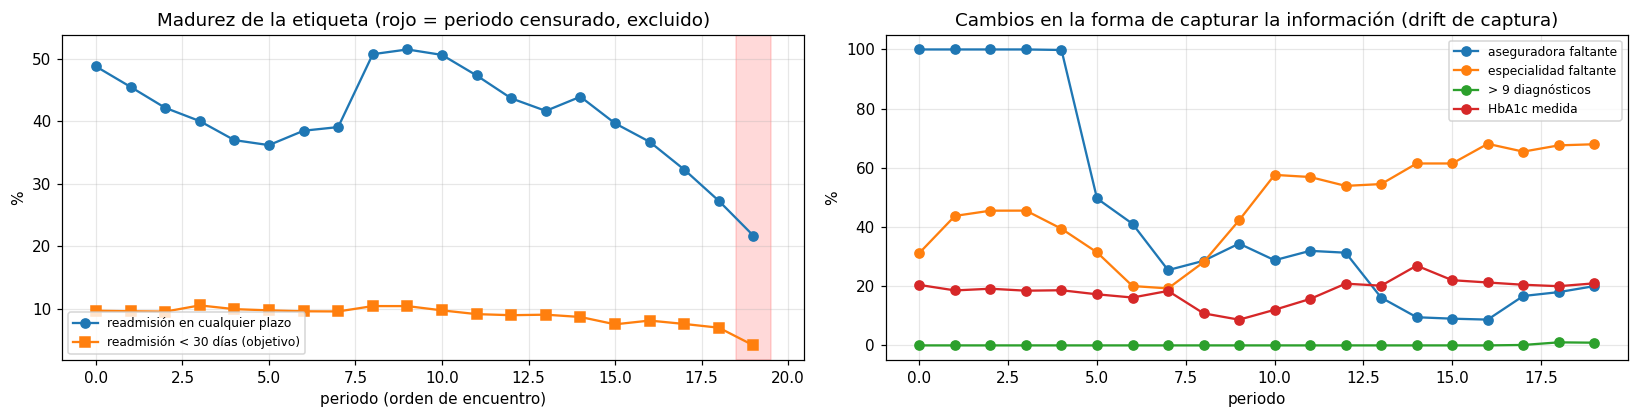

,paso,encuentros
0,Encuentros originales,101766
1,Sin altas por defunción u hospicio,99343
2,Primer encuentro por paciente,69990
3,Sexo registrado,69987
4,Sin periodos con etiqueta censurada [19],66487


In [8]:
with timed("cronologia_y_cohorte"):
    srt = raw_df.sort_values("encounter_id")
    multi = srt[srt.groupby("patient_nbr")["encounter_id"].transform("size") > 1].copy()
    multi["es_ultimo"] = multi.groupby("patient_nbr")["encounter_id"].transform("max") == multi["encounter_id"]
    chrono = multi.groupby("es_ultimo")["readmitted"].apply(lambda s: (s != "NO").mean())
    steps = []
    d = srt.copy()
    steps.append(("Encuentros originales", len(d)))
    d = d[~d["discharge_disposition_id"].isin(EXCLUDED_DISCHARGE)]
    steps.append(("Sin altas por defunción u hospicio", len(d)))
    d = d.drop_duplicates("patient_nbr", keep="first")
    steps.append(("Primer encuentro por paciente", len(d)))
    d = d[d["gender"].isin(["Female", "Male"])].reset_index(drop=True)
    steps.append(("Sexo registrado", len(d)))
    d["y"] = (d["readmitted"] == "<30").astype(int)
    d["any_readmission"] = (d["readmitted"] != "NO").astype(int)
    d["period"] = pd.qcut(np.arange(len(d)), CONFIG["n_periods"], labels=False)
print(f"Verificación cronológica → readmitidos entre encuentros NO últimos: {chrono.get(False, np.nan):.1%} · "
      f"entre los últimos: {chrono.get(True, np.nan):.1%}  (≈100 % vs mucho menor ⇒ encounter_id es cronológico)")
by_period = d.groupby("period").agg(encuentros=("y", "size"), readm_30d=("y", "mean"), readm_cualquiera=("any_readmission", "mean"),
                                    payer_faltante=("payer_code", lambda s: s.isna().mean()),
                                    especialidad_faltante=("medical_specialty", lambda s: s.isna().mean()),
                                    diagnosticos_mas_de_9=("number_diagnoses", lambda s: (s > 9).mean()),
                                    hba1c_medida=("A1Cresult", lambda s: (s != "None").mean()))
rates = by_period["readm_30d"].to_numpy()
censored = []
for pidx in range(len(rates) - 1, 5, -1):
    if rates[pidx] < CONFIG["censor_ratio"] * np.median(rates[pidx - 5:pidx]):
        censored.append(pidx)
    else:
        break
CENSORED_PERIODS = sorted(censored)
cohort = d[~d["period"].isin(CENSORED_PERIODS)].reset_index(drop=True)
steps.append((f"Sin periodos con etiqueta censurada {CENSORED_PERIODS}", len(cohort)))
cohort_steps = pd.DataFrame(steps, columns=["paso", "encuentros"])

fig, ax = plt.subplots(1, 2, figsize=(15, 3.9))
ax[0].plot(by_period.index, 100 * by_period["readm_cualquiera"], "o-", label="readmisión en cualquier plazo")
ax[0].plot(by_period.index, 100 * by_period["readm_30d"], "s-", label="readmisión < 30 días (objetivo)")
for pidx in CENSORED_PERIODS:
    ax[0].axvspan(pidx - 0.5, pidx + 0.5, color="red", alpha=0.15)
ax[0].set_title("Madurez de la etiqueta (rojo = periodo censurado, excluido)")
ax[0].set_xlabel("periodo (orden de encuentro)")
ax[0].set_ylabel("%")
ax[0].legend(fontsize=8)
for c, lab in [("payer_faltante", "aseguradora faltante"), ("especialidad_faltante", "especialidad faltante"),
               ("diagnosticos_mas_de_9", "> 9 diagnósticos"), ("hba1c_medida", "HbA1c medida")]:
    ax[1].plot(by_period.index, 100 * by_period[c], "o-", label=lab)
ax[1].set_title("Cambios en la forma de capturar la información (drift de captura)")
ax[1].set_xlabel("periodo")
ax[1].set_ylabel("%")
ax[1].legend(fontsize=8)
plt.tight_layout()
plt.show()
cohort_steps

**Lectura:**
- **`encounter_id` es cronológico:** los encuentros que no son el último de su paciente están marcados como readmitidos casi siempre. Esto valida el eje temporal que TT1 asumió sin comprobar.
- **La cola final está censurada:** la readmisión en cualquier plazo cae con fuerza en los últimos periodos, porque las readmisiones de > 30 días necesitan más seguimiento. El objetivo < 30 días colapsa en el último periodo. Evaluar ahí castigaría al modelo por etiquetas incompletas, no por drift.
- **Drift de captura:** a lo largo del tiempo cambian con fuerza varias cosas.
  - El faltante de aseguradora cae del 100 % en los primeros periodos a ~10–30 %.
  - El de especialidad sube hasta ~65–70 % en la segunda mitad.
  - Solo al final aparecen registros con más de 9 diagnósticos, señal de un cambio en el sistema de captura.
  - Es drift real de *X*, visible para el PSI (§2.6).

### 1.8 Requisitos de un dataset candidato (observación 4)
`validate_dataset()` es la misma función que en Polish y Airline, con dos requisitos adicionales que este dataset hizo evidentes:

| Requisito | Criterio verificable |
|---|---|
| R11 · Independencia de filas | Una fila por entidad (paciente). |
| R12 · Madurez de la etiqueta | Sin colapso de la tasa del objetivo al final de la serie. |

Se evalúan tres niveles:
- El dataset crudo.
- La cohorte que usó TT1: primer encuentro por paciente, sin excluir la cola censurada.
- La cohorte de TT2.

In [9]:
def runs_test_z(seq):
    """Prueba de rachas de Wald–Wolfowitz para una secuencia binaria (z ≈ 0 si el orden es aleatorio)."""
    s = np.asarray(seq).astype(int)
    n1, n = s.sum(), len(s)
    n0 = n - n1
    if n1 == 0 or n0 == 0:
        return np.nan
    runs = 1 + np.count_nonzero(np.diff(s))
    mu = 2 * n1 * n0 / n + 1
    var = 2 * n1 * n0 * (2 * n1 * n0 - n) / (n ** 2 * (n - 1))
    return (runs - mu) / np.sqrt(var)

def validate_dataset(df, target, period_col, order_col, features, id_cols=(), entity_col=None, block_size=1000, min_blocks=20,
                     min_pos_block=25, min_pos_buffer=100, recal_buffer=3000, prod_frac=0.30, max_missing=0.60,
                     warn_missing=0.30, max_dup=0.01, censor_ratio=0.70):
    """Checklist cuantitativo de idoneidad para estudiar calibration drift (✅ · ⚠️ · ❌)."""
    rows = []

    def add(req, crit, val, ok, warn=False):
        rows.append({"requisito": req, "criterio": crit, "valor": val, "estado": ("⚠️" if warn else "✅") if ok else "❌"})

    y = df[target]
    add("R1 Objetivo binario", "valores ⊆ {0,1}", str(sorted(y.unique().tolist())), set(y.unique()) <= {0, 1})
    n_per = df[period_col].nunique()
    add("R2 Eje temporal", "≥ 3 periodos ordenables", f"{n_per} periodos", n_per >= 3)
    zmax = np.nanmax([abs(runs_test_z(g.sort_values(order_col)[target])) for _, g in df.groupby(period_col)])
    add("R3 Orden independiente de la etiqueta", "|z| de rachas < 3 en cada periodo", f"máx |z| = {zmax:.1f}", zmax < 3)
    n_prod = int(len(df) * prod_frac)
    n_blocks = n_prod // block_size + int(n_prod % block_size >= block_size // 2)
    add("R4 Tamaño de producción", f"≥ {min_blocks} bloques de {block_size} (último ≥ 50 %)", f"{n_blocks} bloques", n_blocks >= min_blocks)
    prev_prod = df.sort_values(order_col)[target].iloc[-n_prod:].mean()
    add("R5 Positivos por bloque", f"≥ {min_pos_block} esperados", f"{prev_prod * block_size:.0f}", prev_prod * block_size >= min_pos_block)
    add("R6 Positivos en buffer de recalibración", f"≥ {min_pos_buffer} en {recal_buffer} filas", f"{prev_prod * recal_buffer:.0f}",
        prev_prod * recal_buffer >= min_pos_buffer)
    miss = df[features].isna().mean()
    add("R7 Faltantes por variable", f"máx ≤ {max_missing:.0%} (⚠️ si > {warn_missing:.0%})", f"{miss.max():.1%} ({miss.idxmax()})",
        miss.max() <= max_missing, warn=miss.max() > warn_missing)
    dup = df.duplicated(subset=features).mean()
    add("R8 Duplicados exactos", f"≤ {max_dup:.0%}", f"{dup:.2%}", dup <= max_dup)
    _, p, _, _ = stats.chi2_contingency(pd.crosstab(df[period_col], df[target]))
    add("R9 Evidencia de no estacionariedad", "χ² de prevalencia entre periodos, p < 0.05", f"p = {p:.1e}", p < 0.05)
    leaked = [c for c in id_cols if c in features]
    add("R10 Sin identificadores ni fugas", "ninguna columna ID o post-desenlace entre las variables", ", ".join(leaked) or "ninguna", not leaked)
    if entity_col is not None:
        rep = 1 - df[entity_col].nunique() / len(df)
        add("R11 Independencia de filas", "una fila por entidad", f"{rep:.1%} filas repetidas por entidad", rep == 0)
    r = df.groupby(period_col)[target].mean().to_numpy()
    tail_ok = r[-1] >= censor_ratio * np.median(r[-6:-1])
    add("R12 Madurez de la etiqueta", f"tasa del último periodo ≥ {censor_ratio:.0%} de la mediana de los 5 previos",
        f"{r[-1]:.3f} vs mediana {np.median(r[-6:-1]):.3f}", tail_ok)
    return pd.DataFrame(rows)

raw_v = raw_df.sort_values("encounter_id").reset_index(drop=True)
raw_v["y"] = (raw_v["readmitted"] == "<30").astype(int)
raw_v["period"] = pd.qcut(np.arange(len(raw_v)), CONFIG["n_periods"], labels=False)
raw_v["orden"] = np.arange(len(raw_v))
d["orden"] = np.arange(len(d))
cohort["orden"] = np.arange(len(cohort))
FEATS_TT1 = [c for c in raw_df.columns if c not in ("encounter_id", "patient_nbr", "readmitted")]
FEATS_TT2 = [c for c in RAW_INPUT if c in cohort.columns]
KW = dict(target="y", period_col="period", order_col="orden", id_cols=("encounter_id", "patient_nbr"), entity_col="patient_nbr",
          block_size=CONFIG["block_size"], recal_buffer=CONFIG["recal_buffer"], prod_frac=1 - CONFIG["train_frac"] - CONFIG["cal_frac"],
          censor_ratio=CONFIG["censor_ratio"])
with timed("validacion_dataset"):
    validation_raw = validate_dataset(raw_v, features=FEATS_TT1, **KW)
    validation_tt1 = validate_dataset(d, features=FEATS_TT2, **KW)
    validation_fixed = validate_dataset(cohort, features=FEATS_TT2, **KW)
validation = validation_raw[["requisito", "criterio"]].assign(
    **{"Dataset crudo": validation_raw["valor"] + "  " + validation_raw["estado"],
       "TT1 · cohorte sin excluir la cola": validation_tt1["valor"] + "  " + validation_tt1["estado"],
       "TT2 · cohorte corregida": validation_fixed["valor"] + "  " + validation_fixed["estado"]})
validation

⏱  validacion_dataset: 3.238 s  (RSS 580 MB)


,requisito,criterio,Dataset crudo,TT1 · cohorte sin excluir la cola,TT2 · cohorte corregida
0,R1 Objetivo binario,"valores ⊆ {0,1}","[0, 1] ✅","[0, 1] ✅","[0, 1] ✅"
1,R2 Eje temporal,≥ 3 periodos ordenables,20 periodos ✅,20 periodos ✅,19 periodos ✅
2,R3 Orden independiente de la etiqueta,|z| de rachas < 3 en cada periodo,máx |z| = 2.2 ✅,máx |z| = 2.1 ✅,máx |z| = 2.1 ✅
3,R4 Tamaño de producción,≥ 20 bloques de 1000 (último ≥ 50 %),31 bloques ✅,21 bloques ✅,20 bloques ✅
4,R5 Positivos por bloque,≥ 25 esperados,107 ✅,72 ✅,80 ✅
5,R6 Positivos en buffer de recalibración,≥ 100 en 3000 filas,322 ✅,216 ✅,239 ✅
6,R7 Faltantes por variable,máx ≤ 60% (⚠️ si > 30%),96.9% (weight) ❌,48.1% (medical_specialty) ⚠️,47.0% (medical_specialty) ⚠️
7,R8 Duplicados exactos,≤ 1%,0.00% ✅,0.00% ✅,0.00% ✅
8,R9 Evidencia de no estacionariedad,"χ² de prevalencia entre periodos, p < 0.05",p = 4.7e-05 ✅,p = 4.0e-29 ✅,p = 1.7e-09 ✅
9,R10 Sin identificadores ni fugas,ninguna columna ID o post-desenlace entre las ...,ninguna ✅,ninguna ✅,ninguna ✅


## 2. Preprocesamiento avanzado y feature engineering
### 2.1 Partición temporal 60/10/30
Sobre la cohorte con etiqueta madura, en orden de encuentro:
- **Train** (60 %): primeros encuentros.
- **Calibración** (10 %).
- **Producción** (30 %): últimos encuentros.

Los bloques nunca se mezclan. La validación interna del modelo usa el último 15 % de train.

In [10]:
n = len(cohort)
i_tr = int(n * CONFIG["train_frac"])
i_ca = int(n * (CONFIG["train_frac"] + CONFIG["cal_frac"]))
cohort["split"] = np.where(cohort.index < i_tr, "train", np.where(cohort.index < i_ca, "calibration", "production"))
idx_tr = cohort.index[cohort["split"] == "train"].to_numpy()
idx_ca = cohort.index[cohort["split"] == "calibration"].to_numpy()
idx_pr = cohort.index[cohort["split"] == "production"].to_numpy()
y_all = cohort["y"].to_numpy()
y_tr, y_ca, y_pr = y_all[idx_tr], y_all[idx_ca], y_all[idx_pr]
split_summary = (cohort.groupby("split").agg(encuentros=("y", "size"), readmisiones_30d=("y", "sum"), tasa=("y", "mean"),
                                             periodos=("period", lambda s: f"{s.min()}–{s.max()}")).loc[["train", "calibration", "production"]])
split_summary["porcentaje"] = 100 * split_summary["encuentros"] / n
split_summary.round(4)

,encuentros,readmisiones_30d,tasa,periodos,porcentaje
split,,,,,
train,39892,3938,0.0987,0–11,59.9997
calibration,6648,611,0.0919,11–13,9.9989
production,19947,1590,0.0797,13–18,30.0014


### 2.2 Faltantes y variables de captura: qué se usa y qué solo se monitorea
Se compara el faltante en train contra producción. Cuando el faltante depende de **cómo** se capturaba la información en cada época, y no del paciente, usar la variable como predictor introduce un atajo que se rompe con el tiempo.

In [11]:
miss_cmp = pd.DataFrame({"faltante_train_%": 100 * cohort.loc[idx_tr].isna().mean(),
                         "faltante_producción_%": 100 * cohort.loc[idx_pr].isna().mean()})
miss_cmp = miss_cmp[(miss_cmp > 0).any(axis=1)].round(1)
miss_cmp["decisión"] = miss_cmp.index.map({
    "weight": "Se descarta: ~97 % faltante",
    "payer_code": "Solo monitoreo: su faltante cambia por captura, no por el paciente",
    "medical_specialty": "Se usa con categoría explícita 'No registrada' (15 más frecuentes + 'Otra')",
    "race": "Se usa con categoría 'Desconocido'",
    "diag_1": "Se agrupa en 9 categorías ICD-9 (faltante → 'Desconocido')",
    "diag_2": "Ídem", "diag_3": "Ídem"}).fillna("—")
miss_cmp

,faltante_train_%,faltante_producción_%,decisión
race,2.8,3.1,Se usa con categoría 'Desconocido'
weight,95.6,96.4,Se descarta: ~97 % faltante
payer_code,63.2,12.3,Solo monitoreo: su faltante cambia por captura...
medical_specialty,37.5,63.6,Se usa con categoría explícita 'No registrada'...
diag_1,0.0,0.0,Se agrupa en 9 categorías ICD-9 (faltante → 'D...
diag_2,0.6,0.2,Ídem
diag_3,2.5,0.7,Ídem


### 2.3 Feature engineering con `DiabetesFeaturizer`
| Transformación | Detalle | Por qué |
|---|---|---|
| IDs administrativos → descripciones del `IDS_mapping` | Tipo de admisión, destino al alta y origen; códigos NULL/No mapeado → *Desconocido* | Son **categorías nominales**; tratarlas como número (TT1) inventa un orden inexistente. |
| ICD-9 → 9 grupos clínicos | Circulatorio, Respiratorio, Digestivo, Diabetes, Lesiones, Musculoesquelético, Genitourinario, Neoplasias, Otros | ~700 códigos distintos por columna; los grupos (Strack et al., 2014) conservan el significado clínico. |
| 23 medicamentos → agregados | N.º de antidiabéticos recetados y con ajuste de dosis; insulina y metformina se conservan individualmente | Evita decenas de columnas casi constantes. |
| Edad → punto medio del rango | `[70-80)` → 75 | La edad es ordinal: el one-hot pierde el orden. |
| Visitas previas | Consulta + urgencias + hospitalización en el año previo | Resume la carga de utilización. |
| HbA1c y glucosa | Con categoría *No medido* | Que no se haya medido es información clínica. |

Los vocabularios (categorías y especialidades frecuentes) se congelan con **train**.

⏱  construccion_variables: 6.307 s  (RSS 596 MB)
Variables del modelo: 27 (12 numéricas + 15 categóricas)


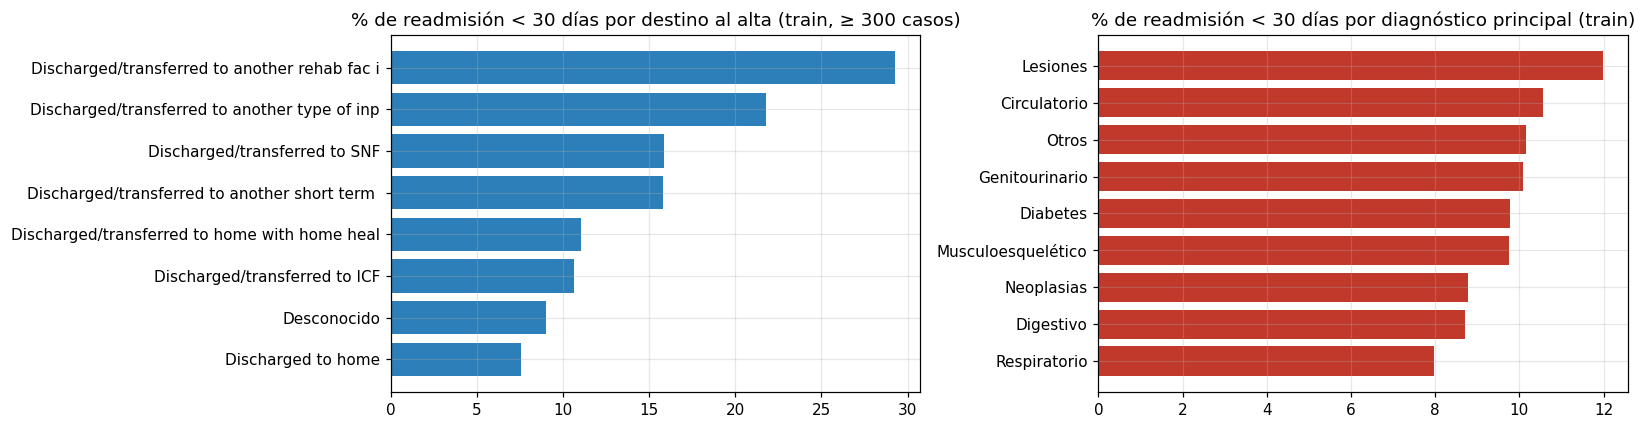

,AUC_univariada_train,descripción
number_diagnoses,0.564,N.º de diagnósticos registrados
time_in_hospital,0.563,Días de hospitalización
prior_visits,0.560,Total de visitas en el año previo
number_inpatient,0.554,Hospitalizaciones en el año previo
num_medications,0.554,N.º de medicamentos distintos
age_mid,0.550,Edad (punto medio del rango)
num_lab_procedures,0.538,N.º de pruebas de laboratorio
n_meds_changed,0.522,N.º de antidiabéticos con dosis ajustada
n_meds_active,0.520,N.º de antidiabéticos recetados
number_emergency,0.514,Visitas a urgencias en el año previo


In [12]:
with timed("construccion_variables"):
    featurizer = DiabetesFeaturizer(IDS, top_specialties=CONFIG["top_specialties"]).fit(cohort.loc[idx_tr])
    X_all = featurizer.transform(cohort)
    B_all = featurizer.base(cohort)
X_tr, X_ca, X_pr = X_all.loc[idx_tr], X_all.loc[idx_ca], X_all.loc[idx_pr]
print(f"Variables del modelo: {X_all.shape[1]} ({len(NUM_FEATURES)} numéricas + {len(CAT_FEATURES)} categóricas)")
rate = lambda col: (B_all.loc[idx_tr].assign(y=y_tr).groupby(col)["y"].agg(["size", "mean"]).query("size >= 300")
                    .sort_values("mean", ascending=False))
disc = rate("discharge_disposition")
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
ax[0].barh([s[:45] for s in disc.index[::-1]], 100 * disc["mean"][::-1], color="#2c7fb8")
ax[0].set_title("% de readmisión < 30 días por destino al alta (train, ≥ 300 casos)")
diag = rate("diag_1_group")
ax[1].barh(diag.index[::-1], 100 * diag["mean"][::-1], color="#c0392b")
ax[1].set_title("% de readmisión < 30 días por diagnóstico principal (train)")
plt.tight_layout()
plt.show()
num_auc = pd.Series({c: roc_auc_score(y_tr, X_tr[c].fillna(X_tr[c].median())) for c in NUM_FEATURES})
pd.DataFrame({"AUC_univariada_train": np.maximum(num_auc, 1 - num_auc), "descripción": pd.Series(FEATURE_LABELS)}).dropna().sort_values(
    "AUC_univariada_train", ascending=False).round(3)

### 2.4 Estrategia de codificación, imputación y desbalance
**Codificación categórica:**
- *XGBoost*: **categorías nativas**; una categoría no vista en producción se trata como faltante.
- *Regresión logística*: **one-hot** con `min_frequency = 100`. Las categorías raras y las no vistas se agrupan en "infrecuente".

**Imputación:**
- En categóricas no hay NaN: cada ausencia tiene una categoría explícita (*Desconocido*, *No registrada*, *No medido*), porque en este dominio la ausencia es informativa.
- En numéricas no hay faltantes en los datos. Para robustez en inferencia (formularios incompletos del dashboard), la LR imputa la mediana de train y XGBoost usa NaN nativo.
- Los conteos muy sesgados (visitas previas, procedimientos) entran a la LR como log(1 + x).

**Desbalance (≈ 9 % de readmisiones):**
- **No** se usan pesos de clase ni remuestreo.
- En TT1, `scale_pos_weight` = 9.1 y `class_weight='balanced'` produjeron un ECE ≈ 0.33–0.40 **en el propio split de calibración**: la miscalibración era autoinducida, no drift. La ablación §3.6 lo cuantifica.
- El desbalance se atiende con AUC-PR y con un umbral que prioriza *recall* (F2, §4.5): omitir una readmisión cuesta más que un seguimiento de más.

In [13]:
print(make_lr_pipeline(C=0.1, min_frequency=CONFIG["onehot_min_frequency"]))

Pipeline(steps=[('prep',
                 ColumnTransformer(transformers=[('cat',
                                                  OneHotEncoder(handle_unknown='infrequent_if_exist',
                                                                min_frequency=100),
                                                  ['race', 'gender',
                                                   'admission_type',
                                                   'discharge_disposition',
                                                   'admission_source',
                                                   'medical_specialty',
                                                   'diag_1_group',
                                                   'diag_2_group',
                                                   'diag_3_group', 'A1Cresult',
                                                   'max_glu_serum', 'insulin',
                                                   'metformin', 'change',
        

### 2.5 ¿Análisis estático o con ajuste de dimensionalidad? (observación 6)
**Postura del proyecto:**
- El análisis exploratorio es **estático**; el monitoreo es **dinámico** (por bloques).
- El **esquema de variables se congela en cada versión del modelo**. Vocabularios, especialidades frecuentes, agrupaciones y lista de variables se ajustan solo con train y se re-estiman únicamente al reentrenar.

**Técnica aplicada:** reducción *guiada por conocimiento del dominio*, no algorítmica:
- Agregación de medicamentos.
- Grupos ICD-9.
- Edad ordinal.
- Agrupación de categorías raras.

Esto conserva variables interpretables para el personal clínico, algo que una proyección como PCA destruiría. La tabla compara el tamaño del espacio de entrada.

In [14]:
dims = pd.DataFrame([
    {"esquema": "Columnas crudas del CSV", "columnas": raw_df.shape[1]},
    {"esquema": "TT1 · matriz de entrada del notebook entregado (one-hot, 23 medicamentos por separado)", "columnas": 148},
    {"esquema": "TT2 · XGBoost (categorías nativas)", "columnas": X_all.shape[1]},
    {"esquema": "TT2 · LR one-hot sin agrupar", "columnas": len(make_lr_pipeline(min_frequency=None)[:-1].fit(X_tr).get_feature_names_out())},
    {"esquema": f"TT2 · LR one-hot con min_frequency = {CONFIG['onehot_min_frequency']}",
     "columnas": len(make_lr_pipeline(min_frequency=CONFIG["onehot_min_frequency"])[:-1].fit(X_tr).get_feature_names_out())},
])
dims

,esquema,columnas
0,Columnas crudas del CSV,50
1,TT1 · matriz de entrada del notebook entregado...,148
2,TT2 · XGBoost (categorías nativas),27
3,TT2 · LR one-hot sin agrupar,123
4,TT2 · LR one-hot con min_frequency = 100,112


### 2.6 Population Stability Index (PSI) a lo largo del tiempo
PSI = Σᵢ (qᵢ − pᵢ)·ln(qᵢ / pᵢ). Numéricas: deciles de la referencia más bin de faltantes. Categóricas: las 30 categorías más frecuentes, más "otras" y faltantes.

**Qué se monitorea:**
- Variables clínicas y administrativas.
- `payer_code`, **solo como monitor de captura**: su faltante cambia con el sistema, no con el paciente.

**Umbrales empíricos:** la referencia se ajusta con una mitad aleatoria de train y la distribución nula de PSI_máx se estima con muestras de la otra mitad.

⏱  psi_por_periodo: 1.259 s  (RSS 613 MB)


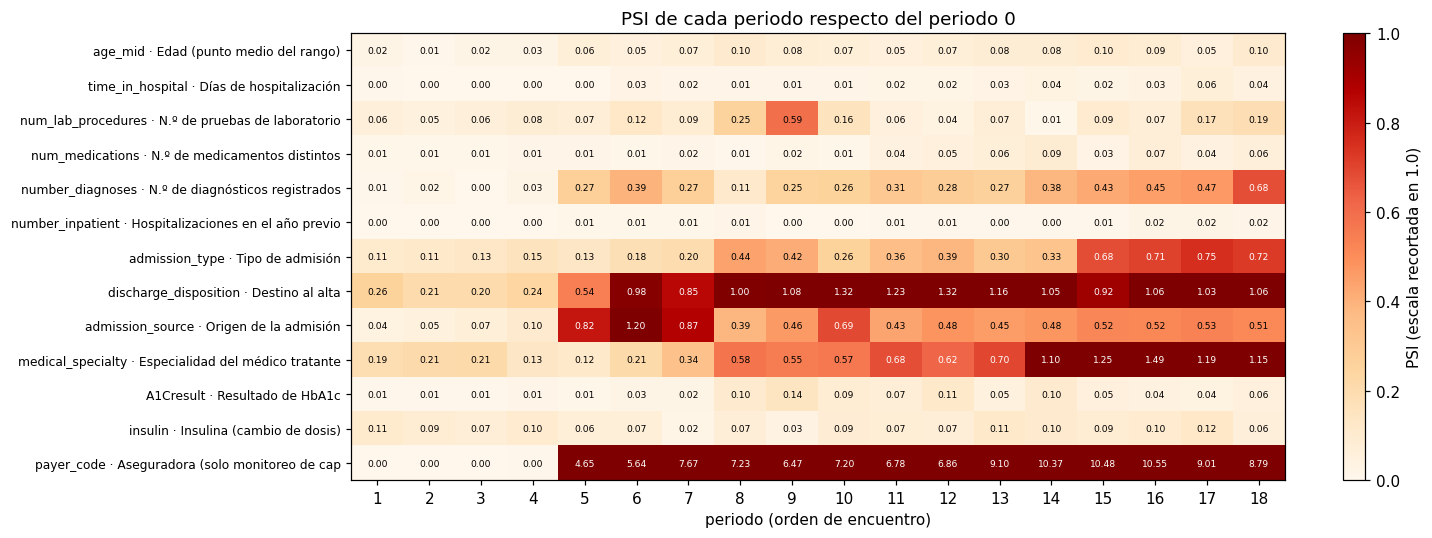

In [15]:
MON_ALL = featurizer.monitor_frame(cohort)
with timed("psi_por_periodo"):
    ref_p0 = PSIReference(n_bins=CONFIG["psi_bins"], max_categories=CONFIG["psi_max_categories"]).fit(MON_ALL[cohort["period"] == 0])
    psi_periods = pd.DataFrame({p: ref_p0.transform(MON_ALL[cohort["period"] == p]) for p in sorted(cohort["period"].unique()) if p > 0})
vals = psi_periods.to_numpy()
fig, ax = plt.subplots(figsize=(14, 5))
im = ax.imshow(vals, cmap="OrRd", aspect="auto", vmin=0, vmax=min(1.0, max(0.25, vals.max())))
ax.set_yticks(range(len(psi_periods)))
ax.set_yticklabels([f"{c} · {FEATURE_LABELS[c][:34]}" for c in psi_periods.index], fontsize=8)
ax.set_xticks(range(vals.shape[1]))
ax.set_xticklabels(psi_periods.columns)
ax.set_xlabel("periodo (orden de encuentro)")
for i in range(vals.shape[0]):
    for j in range(vals.shape[1]):
        ax.text(j, i, f"{vals[i, j]:.2f}", ha="center", va="center", fontsize=6, color="white" if vals[i, j] > 0.6 else "black")
ax.grid(False)
plt.colorbar(im, label="PSI (escala recortada en 1.0)")
ax.set_title("PSI de cada periodo respecto del periodo 0")
plt.tight_layout()
plt.show()

In [16]:
with timed("psi_referencia_train_y_umbrales_nulos"):
    psi_train_ref, null_thr = fit_psi_monitor(MON_ALL.loc[idx_tr], CONFIG["psi_null_sizes"], B=CONFIG["psi_null_B"], seed=SEED,
                                               n_bins=CONFIG["psi_bins"], max_categories=CONFIG["psi_max_categories"])
    psi_null = pd.DataFrame([{"n": n_, **v} for n_, v in null_thr.items()])
    psi_splits = pd.DataFrame({"train→calibración": psi_train_ref.transform(MON_ALL.loc[idx_ca]),
                               "train→producción": psi_train_ref.transform(MON_ALL.loc[idx_pr])})
psi_splits["descripción"] = psi_splits.index.map(FEATURE_LABELS)
print("Umbrales empíricos de PSI_máx (13 variables) sin drift, según tamaño de muestra:")
display(psi_null.round(4))
psi_splits.sort_values("train→producción", ascending=False).round(4)

⏱  psi_referencia_train_y_umbrales_nulos: 13.140 s  (RSS 613 MB)
Umbrales empíricos de PSI_máx (13 variables) sin drift, según tamaño de muestra:


,n,media,p95,p99
0,500,0.0467,0.0727,0.0971
1,1000,0.0240,0.0358,0.0433
2,2000,0.0129,0.0189,0.0214


,train→calibración,train→producción,descripción
payer_code,0.4595,1.3220,Aseguradora (solo monitoreo de captura)
medical_specialty,0.2364,0.5443,Especialidad del médico tratante
discharge_disposition,0.4481,0.3949,Destino al alta
admission_source,0.4586,0.3499,Origen de la admisión
number_diagnoses,0.1917,0.2967,N.º de diagnósticos registrados
admission_type,0.0514,0.1247,Tipo de admisión
insulin,0.0475,0.0980,Insulina (cambio de dosis)
A1Cresult,0.0470,0.0385,Resultado de HbA1c
num_medications,0.0404,0.0380,N.º de medicamentos distintos
num_lab_procedures,0.0451,0.0328,N.º de pruebas de laboratorio


**Lectura: a diferencia de Polish y Airline, aquí sí hay drift fuerte en *X***
- Las variables administrativas y de captura cambian mucho entre train y producción (PSI de décimas hasta más de 1): destino al alta, origen de la admisión, especialidad, número de diagnósticos y, sobre todo, el faltante de aseguradora.
- Varios de estos cambios reflejan **cómo** se registraba la información más que **quién** era el paciente.
- Excluir `payer_code` del modelo y codificar la ausencia de especialidad como categoría explícita reduce la dependencia del modelo en esos artefactos. Aun así, el drift de captura persiste y el monitor debe tolerarlo.
- Los valores de PSI de variables superan con amplitud los umbrales nulos. Una alarma basada en ellos estaría encendida siempre. Por eso, en §4.6 el PSI de variables es **informativo** y las acciones se disparan con el score del modelo y la calibración.

## 3. Modelado y justificación
### 3.1 ¿Por qué Regresión Logística como baseline y XGBoost como modelo avanzado? (observación 2)

**Regresión logística — baseline interpretable (y candidato fuerte en el dominio médico)**
- Minimiza la log-verosimilitud, una *regla de puntuación propia*: bien especificada, produce probabilidades calibradas por construcción (Niculescu-Mizil & Caruana, 2005).
- Es el estándar de los modelos clínicos de riesgo de readmisión (índices tipo LACE/HOSPITAL). Sus coeficientes se leen como razones de momios que el personal de salud entiende y puede auditar.
- Con señal débil (AUC ≈ 0.6–0.7 en la literatura para este dataset), la baja varianza de la LR es una ventaja: los modelos flexibles tienden a sobreajustar ruido. En TT1 XGBoost tuvo AUC 0.86 en train y 0.62 en calibración.
- Se reentrena en fracciones de segundo.

**XGBoost — modelo avanzado**
- Es el estado del arte en datos tabulares (Grinsztajn et al., NeurIPS 2022; Chen & Guestrin, KDD 2016).
- Tiene **categorías nativas**: destinos al alta, especialidades y grupos diagnósticos sin one-hot.
- Captura interacciones clínicamente plausibles (edad × destino al alta, hospitalizaciones previas × diagnóstico) sin especificarlas a mano.
- En TT2 se **regulariza** con fuerza (profundidad 4, `min_child_weight` 50, `reg_lambda` 5, *early stopping*) para evitar el sobreajuste observado en TT1.
- Sus contribuciones SHAP nativas permiten explicar cada predicción en el dashboard.

**Por qué el par:** en un dominio médico con señal débil, la pregunta relevante es si la complejidad adicional aporta algo sobre un modelo lineal auditable. El par permite responderla con evidencia (§3.6–3.7) y comparar cómo se degrada cada uno bajo el mismo drift.

**Decisiones de configuración (iguales en los tres datasets del proyecto)**
- Sin pesos de clase ni remuestreo (§2.4; demostrado en §3.6).
- XGBoost: número de árboles por *early stopping* en una validación temporal interna (último 15 % de train) y reajuste final con todo train.
- Regresión logística: C elegido por log-loss en la misma validación.
- Candidatos descartados (evidencia en §3.7):
  - Random Forest: probabilidades por votación, sesgadas lejos de 0 y 1.
  - Redes neuronales: sin ventaja en tabular y con sobreconfianza conocida (Guo et al., 2017).
  - SVM: sin probabilidades nativas.

### 3.2 Matrices y validación temporal interna

In [17]:
n_fit = int(len(idx_tr) * (1 - CONFIG["inner_val_frac"]))
idx_fit, idx_val = idx_tr[:n_fit], idx_tr[n_fit:]
X_fit, y_fit = X_all.loc[idx_fit], y_all[idx_fit]
X_val, y_val = X_all.loc[idx_val], y_all[idx_val]
print(f"Ajuste: {len(idx_fit):,} encuentros (tasa {y_fit.mean():.2%}) · Validación interna: {len(idx_val):,} (tasa {y_val.mean():.2%})")

Ajuste: 33,908 encuentros (tasa 9.94%) · Validación interna: 5,984 (tasa 9.46%)


### 3.3 Entrenamiento de la Regresión Logística (con medición de tiempo)

In [18]:
%%time
with timed("LR_seleccion_de_C", modelo="LR"):
    lr_search = []
    for C in CONFIG["lr_C_grid"]:
        pipe = make_lr_pipeline(C=C, min_frequency=CONFIG["onehot_min_frequency"]).fit(X_fit, y_fit)
        p = pipe.predict_proba(X_val)[:, 1]
        lr_search.append({"C": C, "LogLoss_val": log_loss(y_val, p), "AUC_val": roc_auc_score(y_val, p), "AP_val": average_precision_score(y_val, p)})
    lr_search = pd.DataFrame(lr_search)
    best_C = float(lr_search.loc[lr_search["LogLoss_val"].idxmin(), "C"])
with timed("LR_entrenamiento_final", modelo="LR"):
    lr_model = make_lr_pipeline(C=best_C, min_frequency=CONFIG["onehot_min_frequency"]).fit(X_tr, y_tr)
print(f"C seleccionado: {best_C}")
display(lr_search.round(4))

⏱  LR_seleccion_de_C: 7.387 s  (RSS 630 MB)
⏱  LR_entrenamiento_final: 1.005 s  (RSS 637 MB)
C seleccionado: 0.01


,C,LogLoss_val,AUC_val,AP_val
0,0.01,0.3047,0.6277,0.1580
1,0.10,0.3058,0.6256,0.1633
2,1.00,0.3065,0.6237,0.1633


CPU times: user 6.58 s, sys: 10.8 ms, total: 6.59 s
Wall time: 8.41 s


### 3.4 Entrenamiento de XGBoost (con medición de tiempo)

⏱  XGB_early_stopping: 1.167 s  (RSS 644 MB)
⏱  XGB_entrenamiento_final: 0.328 s  (RSS 644 MB)
Árboles seleccionados: 41 · validación interna → LogLoss 0.3035 · AUC 0.6327 · AP 0.1624
Brecha de sobreajuste: AUC train 0.6828 (TT1: 0.8609 en train vs 0.6219 en calibración)


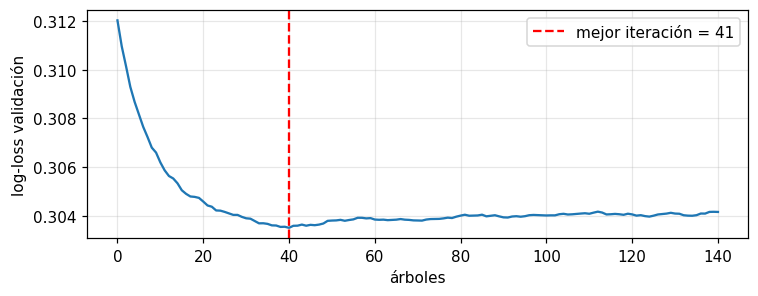

CPU times: user 3.17 s, sys: 29.2 ms, total: 3.2 s
Wall time: 1.76 s


In [19]:
%%time
with timed("XGB_early_stopping", modelo="XGB"):
    xgb_es = XGBClassifier(**XGB_PARAMS, n_estimators=CONFIG["xgb_max_rounds"],
                           early_stopping_rounds=CONFIG["xgb_early_stopping"], eval_metric="logloss")
    xgb_es.fit(X_fit, y_fit, eval_set=[(X_val, y_val)], verbose=False)
    best_iter = int(xgb_es.best_iteration) + 1
with timed("XGB_entrenamiento_final", modelo="XGB"):
    xgb_model = XGBClassifier(**XGB_PARAMS, n_estimators=best_iter).fit(X_tr, y_tr)
p_val = xgb_es.predict_proba(X_val)[:, 1]
p_trn = xgb_model.predict_proba(X_tr)[:, 1]
print(f"Árboles seleccionados: {best_iter} · validación interna → LogLoss {log_loss(y_val, p_val):.4f} · AUC {roc_auc_score(y_val, p_val):.4f} · "
      f"AP {average_precision_score(y_val, p_val):.4f}")
print(f"Brecha de sobreajuste: AUC train {roc_auc_score(y_tr, p_trn):.4f} (TT1: 0.8609 en train vs 0.6219 en calibración)")
curve = xgb_es.evals_result()["validation_0"]["logloss"]
plt.figure(figsize=(7, 2.8))
plt.plot(curve)
plt.axvline(best_iter - 1, color="r", ls="--", label=f"mejor iteración = {best_iter}")
plt.xlabel("árboles")
plt.ylabel("log-loss validación")
plt.legend()
plt.tight_layout()
plt.show()

### 3.5 Protocolo de medición de tiempos (observación 1)
Cada entrenamiento se repite `timing_repeats` veces y cada inferencia 5 veces. Se reporta mediana, mínimo y máximo junto con el hardware; se incluye el costo de construir las variables.

In [20]:
def repeat_timing(fn, repeats):
    out = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        fn()
        out.append(time.perf_counter() - t0)
    return np.array(out)

R_T = CONFIG["timing_repeats"]
X_inf = X_pr.iloc[:1000]
raw_1000 = cohort.loc[idx_pr[:1000]]
ops = [("Construcción de variables (cohorte completa)", len(cohort), R_T, lambda: featurizer.transform(cohort)),
       ("LR · entrenamiento (train completo)", len(X_tr), R_T, lambda: make_lr_pipeline(C=best_C, min_frequency=CONFIG["onehot_min_frequency"]).fit(X_tr, y_tr)),
       ("XGB · entrenamiento (train completo)", len(X_tr), R_T, lambda: XGBClassifier(**XGB_PARAMS, n_estimators=best_iter).fit(X_tr, y_tr)),
       ("Construcción de variables", 1000, 5, lambda: featurizer.transform(raw_1000)),
       ("LR · inferencia", 1000, 5, lambda: lr_model.predict_proba(X_inf)),
       ("XGB · inferencia", 1000, 5, lambda: xgb_model.predict_proba(X_inf))]
with timed("protocolo_de_tiempos"):
    rows = []
    for name, n_rows, reps, fn in ops:
        ts = repeat_timing(fn, reps)
        rows.append({"operación": name, "filas": n_rows, "repeticiones": reps, "mediana_s": np.median(ts),
                     "min_s": ts.min(), "max_s": ts.max(), "ms_por_1000_filas": 1e6 * np.median(ts) / n_rows})
timing_protocol = pd.DataFrame(rows)
print(f"Hardware: {ENV['procesador']} · {ENV['cpus_logicos']} CPU lógicos · {ENV['ram_gb']} GB RAM · "
      f"xgboost {ENV['xgboost']} · scikit-learn {ENV['scikit-learn']} · n_jobs = {CONFIG['n_jobs']}")
timing_protocol.round(4)

⏱  protocolo_de_tiempos: 8.171 s  (RSS 606 MB)
Hardware: x86_64 · 2 CPU lógicos · 13.6 GB RAM · xgboost 3.4.1 · scikit-learn 1.6.1 · n_jobs = 2


,operación,filas,repeticiones,mediana_s,min_s,max_s,ms_por_1000_filas
0,Construcción de variables (cohorte completa),66487,3,0.6982,0.6851,0.7213,10.5006
1,LR · entrenamiento (train completo),39892,3,1.2608,0.9964,1.9169,31.6043
2,XGB · entrenamiento (train completo),39892,3,0.3518,0.3290,0.8495,8.8189
3,Construcción de variables,1000,5,0.0467,0.0434,0.0504,46.7106
4,LR · inferencia,1000,5,0.0163,0.0162,0.0177,16.2535
5,XGB · inferencia,1000,5,0.0084,0.0083,0.0095,8.3898


### 3.6 Ablaciones: evidencia de cada decisión de diseño
Cada variante cambia **una** decisión y se evalúa en el split de **calibración**. Producción queda intacta.

| Variante | Qué pone a prueba |
|---|---|
| TT1 (IDs como número, 23 medicamentos, pesos de clase) | Reproduce el esquema de TT1 para medir la mejora total. |
| Pesos de clase | Su efecto aislado sobre la calibración. |
| IDs como número vs `IDS_mapping` | El aporte de integrar correctamente el diccionario. |
| 23 medicamentos individuales | Dimensionalidad (observación 6). |
| `payer_code` como predictor | El riesgo de aprender artefactos de captura. |
| XGBoost con la configuración de TT1 | 300 árboles, profundidad 5, `scale_pos_weight`: el costo del sobreajuste. |

In [21]:
def eval_row(name, y, p, secs):
    m = evaluate_probs(y, p)
    return {"variante": name, "AUC": m["AUC"], "AP": m["AP"], "Brier": m["Brier"], "LogLoss": m["LogLoss"], "ECE": m["ECE"],
            "prob_media": m["p_media"], "tasa_real": m["prevalencia"], "ajuste_s": secs}

raw_tr, raw_ca = cohort.loc[idx_tr], cohort.loc[idx_ca]

def with_raw_ids(X, raw):
    Z = X.drop(columns=list(ID_COLUMNS.values())).copy()
    for c in ID_COLUMNS:
        Z[c] = pd.to_numeric(raw.loc[X.index, c], errors="coerce").astype(float)
    return Z

def with_meds(X, raw):
    Z = X.copy()
    for m in MEDS:
        if m not in ("insulin", "metformin"):
            Z[f"med_{m}"] = raw.loc[X.index, m].astype(str)
    return Z

def with_payer(X, raw):
    Z = X.copy()
    Z["payer_code"] = raw.loc[X.index, "payer_code"].fillna("No registrada").astype(str).astype(object)
    return Z

CAT_NO_IDS = [c for c in CAT_FEATURES if c not in ID_COLUMNS.values()]
MED_COLS = [f"med_{m}" for m in MEDS if m not in ("insulin", "metformin")]
spw = (y_tr == 0).sum() / (y_tr == 1).sum()

def lr_fit_pred(Xa, Xb, cat, num, cw=None):
    return make_lr_pipeline(C=best_C, class_weight=cw, min_frequency=CONFIG["onehot_min_frequency"], categorical=cat, numeric=num).fit(Xa, y_tr).predict_proba(Xb)[:, 1]

def xgb_frame(X):
    Z = X.copy()
    for c in Z.columns:
        if not pd.api.types.is_numeric_dtype(Z[c]) and not isinstance(Z[c].dtype, pd.CategoricalDtype):
            Z[c] = pd.Categorical(Z[c], categories=sorted(Z[c].dropna().unique()))
    return Z

T1_tr = with_meds(with_raw_ids(X_tr, raw_tr), raw_tr)
T1_ca = with_meds(with_raw_ids(X_ca, raw_ca), raw_ca)
T1_NUM = NUM_FEATURES + list(ID_COLUMNS)
variants = [
    ("LR · esquema TT1 (IDs numéricos + 23 medicamentos + balanced)", lambda: lr_fit_pred(T1_tr, T1_ca, CAT_NO_IDS + MED_COLS, T1_NUM, "balanced")),
    ("LR · TT2 (IDS_mapping, medicamentos agregados, sin pesos)", lambda: lr_fit_pred(X_tr, X_ca, CAT_FEATURES, NUM_FEATURES)),
    ("LR · TT2 + class_weight='balanced'", lambda: lr_fit_pred(X_tr, X_ca, CAT_FEATURES, NUM_FEATURES, "balanced")),
    ("LR · TT2 con IDs como número (sin IDS_mapping)", lambda: lr_fit_pred(with_raw_ids(X_tr, raw_tr), with_raw_ids(X_ca, raw_ca), CAT_NO_IDS, T1_NUM)),
    ("LR · TT2 con los 23 medicamentos individuales", lambda: lr_fit_pred(with_meds(X_tr, raw_tr), with_meds(X_ca, raw_ca), CAT_FEATURES + MED_COLS, NUM_FEATURES)),
    ("LR · TT2 + payer_code como predictor", lambda: lr_fit_pred(with_payer(X_tr, raw_tr), with_payer(X_ca, raw_ca), CAT_FEATURES + ["payer_code"], NUM_FEATURES)),
    ("XGB · configuración TT1 (300 árboles, prof. 5, scale_pos_weight)", lambda: XGBClassifier(n_estimators=300, max_depth=5, learning_rate=0.08, subsample=0.85,
        colsample_bytree=0.85, min_child_weight=3, scale_pos_weight=spw, tree_method="hist", enable_categorical=True, max_cat_to_onehot=1,
        random_state=SEED, n_jobs=CONFIG["n_jobs"]).fit(X_tr, y_tr).predict_proba(X_ca)[:, 1]),
    ("XGB · TT2 (regularizado, sin pesos)", lambda: XGBClassifier(**XGB_PARAMS, n_estimators=best_iter).fit(X_tr, y_tr).predict_proba(X_ca)[:, 1]),
    (f"XGB · TT2 + scale_pos_weight = {spw:.1f}", lambda: XGBClassifier(**XGB_PARAMS, n_estimators=best_iter, scale_pos_weight=spw).fit(X_tr, y_tr).predict_proba(X_ca)[:, 1]),
    ("XGB · TT2 + payer_code como predictor", lambda: XGBClassifier(**XGB_PARAMS, n_estimators=best_iter).fit(xgb_frame(with_payer(X_tr, raw_tr)), y_tr)
        .predict_proba(xgb_frame(with_payer(X_ca, raw_ca)).astype({"payer_code": pd.CategoricalDtype(sorted(with_payer(X_tr, raw_tr)["payer_code"].unique()))}))[:, 1]),
]
abl = []
with timed("ablaciones"):
    for name, run in variants:
        t0 = time.perf_counter()
        p = run()
        abl.append(eval_row(name, y_ca, p, time.perf_counter() - t0))
ablation = pd.DataFrame(abl)
ablation.round(4)

⏱  ablaciones: 14.813 s  (RSS 836 MB)


,variante,AUC,AP,Brier,LogLoss,ECE,prob_media,tasa_real,ajuste_s
0,LR · esquema TT1 (IDs numéricos + 23 medicamen...,0.6323,0.1499,0.2486,0.6915,0.4022,0.4941,0.0919,2.5500
1,"LR · TT2 (IDS_mapping, medicamentos agregados,...",0.6493,0.1580,0.0816,0.2965,0.0151,0.1070,0.0919,1.1023
2,LR · TT2 + class_weight='balanced',0.6525,0.1619,0.2492,0.6951,0.4018,0.4937,0.0919,1.1061
3,LR · TT2 con IDs como número (sin IDS_mapping),0.6340,0.1495,0.0819,0.2985,0.0118,0.1036,0.0919,1.3047
4,LR · TT2 con los 23 medicamentos individuales,0.6482,0.1578,0.0816,0.2966,0.0151,0.1069,0.0919,2.3731
5,LR · TT2 + payer_code como predictor,0.6487,0.1579,0.0815,0.2962,0.0132,0.1048,0.0919,1.9979
6,"XGB · configuración TT1 (300 árboles, prof. 5,...",0.6261,0.1670,0.2058,0.5983,0.3260,0.4179,0.0919,2.7300
7,"XGB · TT2 (regularizado, sin pesos)",0.6557,0.1726,0.0808,0.2941,0.0177,0.1064,0.0919,0.4049
8,XGB · TT2 + scale_pos_weight = 9.1,0.6569,0.1791,0.2409,0.6761,0.3965,0.4884,0.0919,0.3915
9,XGB · TT2 + payer_code como predictor,0.6591,0.1776,0.0806,0.2933,0.0167,0.1047,0.0919,0.4339


**Lectura de las ablaciones:** ver el resumen automático de la celda siguiente.

In [22]:
A = ablation.set_index("variante")
def g(k, c): return A.loc[[i for i in A.index if i.startswith(k)][0], c]
print(f"• Esquema TT1 → TT2 (LR): ECE {g('LR · esquema TT1', 'ECE'):.3f} → {g('LR · TT2 (IDS', 'ECE'):.3f} · "
      f"AP {g('LR · esquema TT1', 'AP'):.3f} → {g('LR · TT2 (IDS', 'AP'):.3f}")
print(f"• Pesos de clase: probabilidad media {g('LR · TT2 + class', 'prob_media'):.3f} (LR) y {g('XGB · TT2 + scale', 'prob_media'):.3f} (XGB) "
      f"frente a una tasa real de {g('LR · TT2 (IDS', 'tasa_real'):.3f} → ECE ×{g('LR · TT2 + class', 'ECE') / g('LR · TT2 (IDS', 'ECE'):.0f} (LR) "
      f"y ×{g('XGB · TT2 + scale', 'ECE') / g('XGB · TT2 (reg', 'ECE'):.0f} (XGB); log-loss {g('LR · TT2 + class', 'LogLoss'):.3f} vs {g('LR · TT2 (IDS', 'LogLoss'):.3f} (LR). "
      f"El AP cambia marginalmente ({g('LR · TT2 + class', 'AP'):.3f} vs {g('LR · TT2 (IDS', 'AP'):.3f} en LR): los pesos no compran detección y sí destruyen la probabilidad.")
print(f"• IDS_mapping vs IDs numéricos (LR): AUC {g('LR · TT2 con IDs', 'AUC'):.4f} → {g('LR · TT2 (IDS', 'AUC'):.4f}")
print(f"• 23 medicamentos individuales vs agregados (LR): AUC {g('LR · TT2 con los 23', 'AUC'):.4f} vs {g('LR · TT2 (IDS', 'AUC'):.4f}")
print(f"• payer_code como predictor: AUC LR {g('LR · TT2 + payer', 'AUC'):.4f} (vs {g('LR · TT2 (IDS', 'AUC'):.4f}), "
      f"XGB {g('XGB · TT2 + payer', 'AUC'):.4f} (vs {g('XGB · TT2 (reg', 'AUC'):.4f}). Ganancia marginal a cambio de depender de una variable cuyo faltante "
      f"pasa de {miss_cmp.loc['payer_code', 'faltante_train_%']:.0f} % en train a {miss_cmp.loc['payer_code', 'faltante_producción_%']:.0f} % en producción: se excluye.")
print(f"• XGB TT1 vs TT2: AUC {g('XGB · configuración TT1', 'AUC'):.4f} → {g('XGB · TT2 (reg', 'AUC'):.4f} · ECE {g('XGB · configuración TT1', 'ECE'):.3f} → {g('XGB · TT2 (reg', 'ECE'):.3f}")

• Esquema TT1 → TT2 (LR): ECE 0.402 → 0.015 · AP 0.150 → 0.158
• Pesos de clase: probabilidad media 0.494 (LR) y 0.488 (XGB) frente a una tasa real de 0.092 → ECE ×27 (LR) y ×22 (XGB); log-loss 0.695 vs 0.296 (LR). El AP cambia marginalmente (0.162 vs 0.158 en LR): los pesos no compran detección y sí destruyen la probabilidad.
• IDS_mapping vs IDs numéricos (LR): AUC 0.6340 → 0.6493
• 23 medicamentos individuales vs agregados (LR): AUC 0.6482 vs 0.6493
• payer_code como predictor: AUC LR 0.6487 (vs 0.6493), XGB 0.6591 (vs 0.6557). Ganancia marginal a cambio de depender de una variable cuyo faltante pasa de 63 % en train a 12 % en producción: se excluye.
• XGB TT1 vs TT2: AUC 0.6261 → 0.6557 · ECE 0.326 → 0.018


### 3.7 Benchmark ampliado de candidatos (evidencia para la observación 2)
Todos con las mismas variables TT2, entrenados en train y evaluados en calibración. Random Forest y la MLP usan la matriz one-hot de la LR.

In [23]:
bench = []
if CONFIG["run_extended_benchmark"]:
    with timed("benchmark_ampliado"):
        pre = make_lr_pipeline(min_frequency=CONFIG["onehot_min_frequency"])[:-1].fit(X_tr)
        Z_tr, Z_ca = pre.transform(X_tr), pre.transform(X_ca)
        cat_mask = [c in CAT_FEATURES for c in X_tr.columns]
        O_tr = X_tr.copy()
        O_ca = X_ca.copy()
        for c in CAT_FEATURES:
            O_tr[c] = O_tr[c].cat.codes.replace(-1, np.nan).astype(float)
            O_ca[c] = O_ca[c].cat.codes.replace(-1, np.nan).astype(float)
        candidates = [
            ("Regresión logística (TT2)", lambda: make_lr_pipeline(C=best_C, min_frequency=CONFIG["onehot_min_frequency"]).fit(X_tr, y_tr).predict_proba(X_ca)[:, 1]),
            ("XGBoost (TT2)", lambda: XGBClassifier(**XGB_PARAMS, n_estimators=best_iter).fit(X_tr, y_tr).predict_proba(X_ca)[:, 1]),
            ("HistGradientBoosting (categorías nativas)", lambda: HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, categorical_features=cat_mask,
                                                                                                early_stopping=True, random_state=SEED).fit(O_tr, y_tr).predict_proba(O_ca)[:, 1]),
            ("Random Forest (300 árboles)", lambda: RandomForestClassifier(n_estimators=300, min_samples_leaf=20, n_jobs=CONFIG["n_jobs"],
                                                                           random_state=SEED).fit(Z_tr, y_tr).predict_proba(Z_ca)[:, 1]),
            ("MLP (64-32, early stopping)", lambda: MLPClassifier(hidden_layer_sizes=(64, 32), early_stopping=True, max_iter=200,
                                                                   random_state=SEED).fit(Z_tr, y_tr).predict_proba(Z_ca)[:, 1]),
        ]
        for name, run in candidates:
            t0 = time.perf_counter()
            p = run()
            bench.append(eval_row(name, y_ca, p, time.perf_counter() - t0))
benchmark = pd.DataFrame(bench)
benchmark.sort_values("LogLoss").round(4) if len(benchmark) else "Benchmark ampliado desactivado en CONFIG"

⏱  benchmark_ampliado: 69.281 s  (RSS 756 MB)


,variante,AUC,AP,Brier,LogLoss,ECE,prob_media,tasa_real,ajuste_s
2,HistGradientBoosting (categorías nativas),0.6614,0.1809,0.0807,0.2930,0.0163,0.1083,0.0919,1.1177
1,XGBoost (TT2),0.6557,0.1726,0.0808,0.2941,0.0177,0.1064,0.0919,0.3904
4,"MLP (64-32, early stopping)",0.6449,0.1699,0.0813,0.2964,0.0056,0.0947,0.0919,6.2150
0,Regresión logística (TT2),0.6493,0.1580,0.0816,0.2965,0.0151,0.1070,0.0919,1.0461
3,Random Forest (300 árboles),0.6486,0.1580,0.0816,0.2968,0.0161,0.1079,0.0919,59.3425


**Lectura del benchmark:**
- Con señal débil, las diferencias entre candidatos son pequeñas. La LR y los modelos de boosting quedan cerca.
- HistGradientBoosting, de la misma familia que XGBoost, puede quedar ligeramente arriba: confirma que el boosting es la familia adecuada. Se mantiene XGBoost por sus contribuciones SHAP nativas y por consistencia entre los tres datasets del proyecto.
- Eso respalda el par elegido:
  - La **LR** como referencia auditable, preferible en contexto clínico cuando la diferencia es marginal.
  - **XGBoost** como el mejor representante de los modelos flexibles, con costo de entrenamiento bajo.
- La MLP y Random Forest no aportan mejora que justifique su costo o su menor interpretabilidad.

## 4. Calibración y evaluación avanzada
### 4.1 Selección del calibrador en el split de calibración
| Método | Qué hace | Cuándo conviene |
|---|---|---|
| `none` | Deja la probabilidad del modelo. | Si ya está calibrado. |
| `temperature` | σ(logit(p)/T): un parámetro, escala la confianza. | Sobre/subconfianza simétrica. No corrige un sesgo de prevalencia. |
| `platt` | σ(a·logit(p)+b): escala **y** sesgo. | Pocos datos y cambios de prevalencia. |
| `isotonic` | Función monótona no paramétrica. | Muchos positivos. Aquí hay ~600 readmisiones en calibración, así que es arriesgada. |

**Procedimiento de elección:**
- Se elige por **log-loss con validación cruzada estratificada de 5 pliegues** dentro del split de calibración.
- Después se ajusta el calibrador elegido con todo el split.
- El modelo recomendado se escoge con el mismo criterio, **sin mirar producción**.

In [24]:
def crossfit_calibrators(p_raw, y, methods, n_splits, seed):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    oof = {m: np.zeros_like(p_raw) for m in methods}
    for tr_i, te_i in skf.split(p_raw.reshape(-1, 1), y):
        for m in methods:
            oof[m][te_i] = make_calibrator(m).fit(p_raw[tr_i], y[tr_i]).predict(p_raw[te_i])
    rows = [{"método": m, "LogLoss": log_loss(y, oof[m]), "Brier": np.mean((oof[m] - y) ** 2),
             "ECE": ece_uniform(y, oof[m]), "ACE": diabetes_tt2.ace_equal_mass(y, oof[m])} for m in methods]
    return pd.DataFrame(rows), oof

MODELS = {"lr": lr_model, "xgb": xgb_model}

def raw_scores(model, X):
    return model.predict_proba(X)[:, 1]

raw_cal = {k: raw_scores(m, X_ca) for k, m in MODELS.items()}
calib_rows, OOF, CALIBRATOR, CAL_METHOD = [], {}, {}, {}
with timed("seleccion_y_ajuste_de_calibradores"):
    for kind, p in raw_cal.items():
        tbl_c, oof = crossfit_calibrators(p, y_ca, CONFIG["calib_methods"], CONFIG["calib_cv_folds"], SEED)
        tbl_c.insert(0, "modelo", kind.upper())
        calib_rows.append(tbl_c)
        CAL_METHOD[kind] = tbl_c.loc[tbl_c["LogLoss"].idxmin(), "método"]
        OOF[kind] = oof[CAL_METHOD[kind]]
        CALIBRATOR[kind] = make_calibrator(CAL_METHOD[kind]).fit(p, y_ca)
calib_sel = pd.concat(calib_rows, ignore_index=True)
cv_best = calib_sel.loc[calib_sel.groupby("modelo")["LogLoss"].idxmin()].sort_values("LogLoss")
BEST_KIND = cv_best.iloc[0]["modelo"].lower()
for k, c in CALIBRATOR.items():
    params = {a: round(getattr(c, a), 4) for a in ("T_", "a_", "b_") if hasattr(c, a)}
    print(f"{k.upper()}: calibrador elegido = {CAL_METHOD[k]} {params}")
print(f"Modelo recomendado para el dashboard: {BEST_KIND.upper()} (menor log-loss validada en el split de calibración)")
calib_sel.round(4)

⏱  seleccion_y_ajuste_de_calibradores: 0.216 s  (RSS 756 MB)
LR: calibrador elegido = temperature {'T_': 0.9233}
XGB: calibrador elegido = platt {'a_': 1.1939, 'b_': 0.2243}
Modelo recomendado para el dashboard: XGB (menor log-loss validada en el split de calibración)


,modelo,método,LogLoss,Brier,ECE,ACE
0,LR,none,0.2965,0.0816,0.0151,0.0151
1,LR,temperature,0.2952,0.0814,0.0067,0.0066
2,LR,platt,0.2954,0.0814,0.0068,0.0044
3,LR,isotonic,0.2996,0.0817,0.0033,0.0078
4,XGB,none,0.2941,0.0808,0.0177,0.0145
5,XGB,temperature,0.2926,0.0806,0.0046,0.0055
6,XGB,platt,0.2926,0.0806,0.0056,0.0058
7,XGB,isotonic,0.2943,0.0807,0.0020,0.0095


### 4.2 Evaluación en producción con intervalos de confianza (incluye KS)
Métricas sobre el 30 % final de la cohorte, con intervalos al 95 % por bootstrap.

| Métrica | Qué mide | Ideal |
|---|---|---|
| **AUC / AP** | Capacidad de ordenar a quienes reingresan por encima de quienes no. El AP es la precisión promedio en la clase rara (azar = prevalencia). | 1 |
| **Brier / BSS** | Error cuadrático / mejora sobre predecir siempre la tasa de train. | 0 / > 0 |
| **ECE / ACE / MCE** | Brecha probabilidad–frecuencia (bins uniformes / igual masa / peor bin). | 0 |
| **CITL / Pendiente** | Calibración en lo grande / dispersión. Son las métricas estándar de validación clínica (TRIPOD). | 0 / 1 |
| **O/E** | Readmisiones observadas / esperadas. | 1 |
| **KS** | Máxima separación entre las distribuciones de score de readmitidos y no readmitidos. | 1 |

**Análisis de sensibilidad:** se reporta también el modelo recomendado evaluado **incluyendo** el periodo censurado, para mostrar cuánto habría distorsionado la evaluación.

In [25]:
def bootstrap_ci(y, p, B, seed, fns):
    rng, n_ = np.random.default_rng(seed), len(y)
    res = {k: [] for k in fns}
    for _ in range(B):
        i = rng.integers(0, n_, n_)
        if y[i].min() == y[i].max():
            continue
        for k, f in fns.items():
            res[k].append(f(y[i], p[i]))
    return {k: np.percentile(v, [2.5, 97.5]) for k, v in res.items()}

CI_FNS = {"AUC": roc_auc_score, "AP": average_precision_score, "Brier": lambda y, p: np.mean((p - y) ** 2), "ECE": ece_uniform}
prior_train = y_tr.mean()
PROD_PROBS = {}
for k, m in MODELS.items():
    PROD_PROBS[f"{k.upper()} · sin calibrar"] = raw_scores(m, X_pr)
    PROD_PROBS[f"{k.upper()} · calibrada ({CAL_METHOD[k]})"] = CALIBRATOR[k].predict(PROD_PROBS[f"{k.upper()} · sin calibrar"])

rows = []
with timed("evaluacion_produccion_bootstrap"):
    for name, p in PROD_PROBS.items():
        m = evaluate_probs(y_pr, p, prior=prior_train)
        ci = bootstrap_ci(y_pr, p, CONFIG["bootstrap_B"], SEED, CI_FNS)
        row = {"modelo": name}
        for k in ["AUC", "AP", "Brier", "ECE"]:
            row[k] = f"{m[k]:.4f} [{ci[k][0]:.4f}, {ci[k][1]:.4f}]"
        row.update({k: round(m[k], 4) for k in ["BSS", "LogLoss", "ACE", "MCE", "CITL", "Pendiente", "O/E", "KS"]})
        row["KS_p"] = f"{m['KS_p']:.1e}"
        rows.append(row)
    BEST_LABEL = f"{BEST_KIND.upper()} · calibrada ({CAL_METHOD[BEST_KIND]})"
    cens_rows = d[d["period"].isin(CENSORED_PERIODS)]
    if len(cens_rows):
        Xc = featurizer.transform(cens_rows)
        y_ext = np.concatenate([y_pr, cens_rows["y"].to_numpy()])
        p_ext = np.concatenate([PROD_PROBS[BEST_LABEL], CALIBRATOR[BEST_KIND].predict(raw_scores(MODELS[BEST_KIND], Xc))])
        m = evaluate_probs(y_ext, p_ext, prior=prior_train)
        rows.append({"modelo": f"{BEST_LABEL} · INCLUYENDO periodo censurado (sensibilidad)",
                     **{k: f"{m[k]:.4f}" for k in ["AUC", "AP", "Brier", "ECE"]},
                     **{k: round(m[k], 4) for k in ["BSS", "LogLoss", "ACE", "MCE", "CITL", "Pendiente", "O/E", "KS"]}, "KS_p": f"{m['KS_p']:.1e}"})
metrics_production = pd.DataFrame(rows)
print(f"Producción: {len(y_pr):,} encuentros · {int(y_pr.sum())} readmisiones < 30 días ({y_pr.mean():.2%}) · tasa en train {prior_train:.2%}")
metrics_production

⏱  evaluacion_produccion_bootstrap: 14.097 s  (RSS 756 MB)
Producción: 19,947 encuentros · 1590 readmisiones < 30 días (7.97%) · tasa en train 9.87%


,modelo,AUC,AP,Brier,ECE,BSS,LogLoss,ACE,MCE,CITL,Pendiente,O/E,KS,KS_p
0,LR · sin calibrar,"0.6218 [0.6061, 0.6346]","0.1308 [0.1225, 0.1440]","0.0731 [0.0704, 0.0761]","0.0280 [0.0241, 0.0316]",0.0078,0.2754,0.0280,0.1351,-0.3397,0.8969,0.7402,0.1852,2.0e-44
1,LR · calibrada (temperature),"0.6218 [0.6061, 0.6346]","0.1308 [0.1225, 0.1440]","0.0725 [0.0697, 0.0755]","0.0133 [0.0096, 0.0170]",0.0167,0.2722,0.0150,0.0778,-0.1737,0.8281,0.8568,0.1852,2.0e-44
2,XGB · sin calibrar,"0.6228 [0.6065, 0.6352]","0.1359 [0.1246, 0.1489]","0.0727 [0.0699, 0.0757]","0.0263 [0.0227, 0.0299]",0.0135,0.2742,0.0263,0.0595,-0.3206,1.0181,0.7518,0.1813,1.6e-42
3,XGB · calibrada (platt),"0.6228 [0.6065, 0.6352]","0.1359 [0.1246, 0.1489]","0.0722 [0.0693, 0.0753]","0.0115 [0.0079, 0.0151]",0.0203,0.2712,0.0125,0.0448,-0.1516,0.8518,0.8739,0.1813,1.6e-42
4,XGB · calibrada (platt) · INCLUYENDO periodo c...,0.6258,0.1304,0.0677,0.0168,0.0218,0.2581,0.0168,0.0422,-0.2294,0.8837,0.8147,0.1898,3.8e-51


**Lectura:**
- La tasa de readmisión en producción es menor que en train (label shift). El modelo calibrado en el periodo de calibración queda más cerca que el crudo, pero sigue **sobreestimando levemente** el riesgo (O/E < 1). Ese drift residual es el que deben absorber las políticas de §4.6.
- La fila de sensibilidad muestra que, sin excluir la cola censurada, el O/E y el ECE empeoran por etiquetas incompletas, no por el modelo.

### 4.3 Diagramas de confiabilidad y separación KS
Bins de igual masa (10 grupos con el mismo número de pacientes). Un modelo calibrado sigue la diagonal.

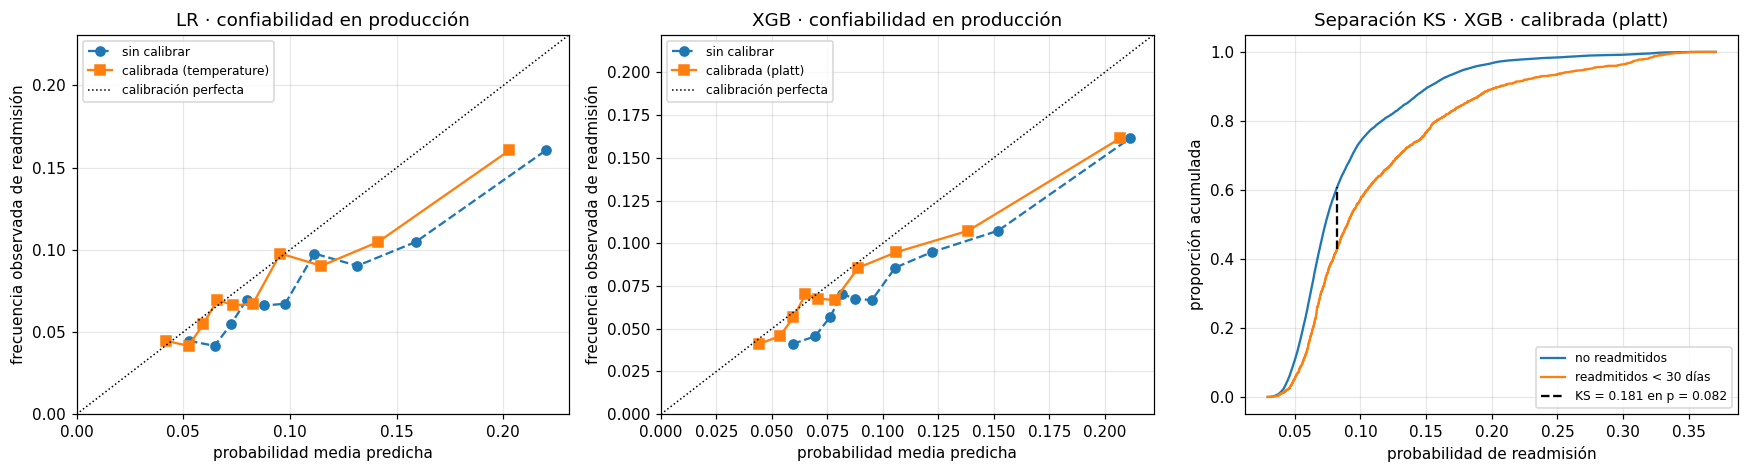

In [26]:
best_p = PROD_PROBS[BEST_LABEL]
rel_rows = []
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
for ax, kind in zip(axes[:2], ["lr", "xgb"]):
    lim = 0
    for label, style in [(f"{kind.upper()} · sin calibrar", "o--"), (f"{kind.upper()} · calibrada ({CAL_METHOD[kind]})", "s-")]:
        rt = reliability_table(y_pr, PROD_PROBS[label], n_bins=10, strategy="quantile")
        rel_rows.append(rt.assign(modelo=label))
        ax.plot(rt["p_media"], rt["frecuencia_observada"], style, label=label.split(" · ")[1])
        lim = max(lim, rt["p_media"].max(), rt["frecuencia_observada"].max())
    ax.plot([0, lim * 1.05], [0, lim * 1.05], "k:", lw=1, label="calibración perfecta")
    ax.set_xlim(0, lim * 1.05)
    ax.set_ylim(0, lim * 1.05)
    ax.set_title(f"{kind.upper()} · confiabilidad en producción")
    ax.set_xlabel("probabilidad media predicha")
    ax.set_ylabel("frecuencia observada de readmisión")
    ax.legend(fontsize=8)
s1, s0 = np.sort(best_p[y_pr == 1]), np.sort(best_p[y_pr == 0])
grid_ = np.unique(np.concatenate([s0, s1]))
F1 = np.searchsorted(s1, grid_, side="right") / len(s1)
F0 = np.searchsorted(s0, grid_, side="right") / len(s0)
j = int(np.argmax(np.abs(F0 - F1)))
ax = axes[2]
ax.plot(grid_, F0, label="no readmitidos")
ax.plot(grid_, F1, label="readmitidos < 30 días")
ax.vlines(grid_[j], F1[j], F0[j], colors="k", linestyles="--", label=f"KS = {abs(F0[j] - F1[j]):.3f} en p = {grid_[j]:.3f}")
ax.set_title(f"Separación KS · {BEST_LABEL}")
ax.set_xlabel("probabilidad de readmisión")
ax.set_ylabel("proporción acumulada")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
reliability_bins = pd.concat(rel_rows, ignore_index=True)

### 4.4 Piso de ruido del ECE: ¿qué valor es alcanzable?
Aun un modelo perfectamente calibrado muestra ECE > 0 en muestras finitas. Se simula y ~ Bernoulli(p) con la distribución real de probabilidades del modelo recomendado.

In [27]:
rng_nf = np.random.default_rng(SEED)
floor = []
for n_ in [500, CONFIG["block_size"], CONFIG["recal_buffer"], len(y_pr)]:
    e = []
    for _ in range(500):
        q = rng_nf.choice(best_p, n_, replace=True)
        e.append(ece_uniform(rng_nf.binomial(1, q), q))
    floor.append({"n": n_, "ECE_esperado_con_calibracion_perfecta": np.mean(e), "p95": np.percentile(e, 95)})
noise_floor = pd.DataFrame(floor)
noise_floor.round(4)

,n,ECE_esperado_con_calibracion_perfecta,p95
0,500,0.0175,0.0312
1,1000,0.0125,0.0226
2,3000,0.0071,0.0126
3,19947,0.0028,0.0051


### 4.5 Umbral de decisión y bandas de riesgo para el dashboard
- **Umbral de alerta:** maximiza F2 (el *recall* pesa el doble). Omitir a un paciente que reingresará cuesta más que un seguimiento de más. Se elige con las predicciones fuera de pliegue del split de calibración.
- **Bandas de riesgo** sobre la probabilidad calibrada: Bajo < 8 % ≤ Medio < 15 % ≤ Alto. El 8 % ≈ tasa base de producción y el 15 % ≈ el doble. Si el modelo está calibrado, la tasa observada en cada banda debe caer dentro de su rango.
- **Nota operativa:**
  - Con señal débil (AUC ≈ 0.62), priorizar el *recall* implica alertar a una fracción grande de pacientes.
  - Si el hospital tiene recursos limitados de seguimiento, la banda **Alto** concentra un subconjunto pequeño con una tasa de readmisión cercana al doble de la base.
  - El dashboard debe mostrar ambas vistas.

In [28]:
def best_fbeta_threshold(y, p, beta):
    grid_t = np.unique(np.quantile(p, np.linspace(0.30, 0.995, 300)))
    scores = [fbeta_score(y, (p >= t).astype(int), beta=beta, zero_division=0) for t in grid_t]
    return float(grid_t[int(np.argmax(scores))])

THRESHOLDS = {k: best_fbeta_threshold(y_ca, OOF[k], CONFIG["fbeta"]) for k in MODELS}
THRESHOLD = THRESHOLDS[BEST_KIND]
yhat = (best_p >= THRESHOLD).astype(int)
print(f"Umbrales F{CONFIG['fbeta']:.0f} (calibración, fuera de pliegue): " + ", ".join(f"{k.upper()} = {v:.4f}" for k, v in THRESHOLDS.items()))
print(f"{BEST_LABEL} en producción → recall {recall_score(y_pr, yhat):.3f} · precisión {precision_score(y_pr, yhat):.3f} · "
      f"F2 {fbeta_score(y_pr, yhat, beta=2.0):.3f} · pacientes alertados {yhat.mean():.1%}")
display(pd.DataFrame(confusion_matrix(y_pr, yhat), index=["real: no reingresa", "real: reingresa"], columns=["pred: no", "pred: sí"]))
cuts = CONFIG["risk_cuts"]
bands = pd.cut(best_p, [0, *cuts, 1.0 + 1e-9], labels=["Bajo", "Medio", "Alto"], right=False, include_lowest=True)
band_tbl = (pd.DataFrame({"banda": bands, "y": y_pr, "p": best_p}).groupby("banda", observed=False)
            .agg(pacientes=("y", "size"), readmisiones=("y", "sum"), prob_media=("p", "mean"), tasa_observada=("y", "mean")))
band_tbl.round(4)

Umbrales F2 (calibración, fuera de pliegue): LR = 0.0841, XGB = 0.0762
XGB · calibrada (platt) en producción → recall 0.624 · precisión 0.106 · F2 0.315 · pacientes alertados 47.1%


,pred: no,pred: sí
real: no reingresa,9949,8408
real: reingresa,598,992


,pacientes,readmisiones,prob_media,tasa_observada
banda,,,,
Bajo,11382,653,0.0609,0.0574
Medio,6241,565,0.1061,0.0905
Alto,2324,372,0.1994,0.1601


### 4.6 Monitoreo por bloques y políticas de intervención (evaluación prequential)
**En palabras simples:**
- Producción llega en bloques de 1 000 pacientes dados de alta.
- Una readmisión a 30 días solo se conoce **30 días después** del alta. Por eso la etiqueta de cada bloque está disponible un bloque más tarde.
- Antes de puntuar cada bloque, el monitor revisa tres señales y cada política decide si interviene con la información disponible en ese momento.

**Señales del monitor (umbrales empíricos):**

| Señal | Qué compara | Necesita etiquetas | Nivel 1 / Nivel 2 | Rol |
|---|---|---|---|---|
| PSI del score | Scores del bloque vs scores de referencia | No | percentil 95 / 99 de su distribución nula | **Dispara acciones** |
| z de calibración | (readmisiones observadas − esperadas) / √Σp(1−p) del bloque anterior | Sí, con retraso | percentil 95 / 99 de \|z\| sin drift (predicciones fuera de pliegue) | **Dispara acciones** |
| PSI_máx de variables | Bloque vs train (13 variables, incluida la captura de aseguradora) | No | percentil 95 / 99 de su distribución nula | Informativa (vista P3): el drift de captura la mantendría encendida siempre |

**Políticas comparadas** (mismos bloques, mismas señales; buffer = últimas 3 000 etiquetas disponibles):
- **Sin calibrar (TT1):** probabilidad cruda.
- **Baseline calibrado:** calibrador de §4.1, fijo.
- **A · Recalibración:** ante alerta ≥ 1, Platt con el buffer.
- **B · Reentrenamiento:** ante alerta nivel 2 (enfriamiento de 2 bloques), reentrena con train + etiquetas acumuladas salvo el buffer, y calibra con el buffer.
- **C · Híbrida:**
  - Recalibra ante alerta.
  - Escala a reentrenamiento si la z sigue en nivel 2 tras recalibrar.
  - Reentrena por **calendario** cada 8 bloques (frecuencia mínima del protocolo).
- **Oráculo (in-sample):** Platt con las etiquetas del **mismo** bloque que evalúa (lo que hacía TT1). No es implementable; es una cota de referencia.

Tras cada intervención, la referencia del score pasa a ser el buffer reciente (**acuse de recibo**).

In [29]:
B_SIZE, L_BUF = CONFIG["block_size"], CONFIG["recal_buffer"]
blocks = [np.arange(s, min(s + B_SIZE, len(idx_pr))) for s in range(0, len(idx_pr), B_SIZE)]
blocks = [b for b in blocks if len(b) >= B_SIZE // 2]
FEAT_THR = null_thr[B_SIZE]
Z_THR = {k: z_null_thresholds(y_ca, OOF[k], n=B_SIZE, B=500, seed=SEED) for k in MODELS}
print("Umbrales |z| (p95 / p99): " + ", ".join(f"{k.upper()} = ({v['p95']:.2f}, {v['p99']:.2f})" for k, v in Z_THR.items()) + " · teóricos N(0,1): 1.96 / 2.58")
POLICIES = ["Sin calibrar (TT1)", "Baseline calibrado", "A · Recalibración", "B · Reentrenamiento", "C · Híbrida", "Oráculo (in-sample)"]
MON_PR = MON_ALL.loc[idx_pr]

def fit_model(kind, X, y):
    if kind == "xgb":
        return XGBClassifier(**XGB_PARAMS, n_estimators=best_iter).fit(X, y)
    return make_lr_pipeline(C=best_C, min_frequency=CONFIG["onehot_min_frequency"]).fit(X, y)

def score_reference(scores, seed, n=None):
    ref, thr = fit_psi_monitor(pd.DataFrame({"score": scores}), [n or B_SIZE], B=CONFIG["psi_null_B"], seed=seed, n_bins=CONFIG["psi_bins"])
    return ref, thr[n or B_SIZE]

def level(v, thr):
    return 2 if v >= thr["p99"] else (1 if v >= thr["p95"] else 0)

def compute_signals(mon, s_raw, prev, feat_ref, feat_thr, s_ref, s_thr, z_thr):
    fpsi = float(feat_ref.transform(mon).max())
    spsi = float(s_ref.transform(pd.DataFrame({"score": s_raw})).iloc[0])
    z = np.nan if prev is None else calibration_z(*prev)
    lf, ls = level(fpsi, feat_thr), level(spsi, s_thr)
    lc = 0 if np.isnan(z) else level(abs(z), z_thr)
    return {"psi_variables_max": fpsi, "psi_score": spsi, "z_calibracion": z, "nivel_variables_info": lf,
            "nivel_score": ls, "nivel_calibracion": lc, "alerta": max(ls, lc)}

ISSUED = {}

def simulate(kind, policy):
    model = MODELS[kind]
    calib = IdentityCalibrator() if policy == "Sin calibrar (TT1)" else CALIBRATOR[kind]
    s_ref, s_thr = score_reference(raw_scores(model, X_ca), SEED)
    pool_X, pool_y = [X_ca], [y_ca]
    last_retrain, last_recal, prev = 0, -10 ** 6, None
    rows, all_y, all_p = [], [], []
    for t, b in enumerate(blocks):
        Xb, yb = X_pr.iloc[b], y_pr[b]
        s_raw = raw_scores(model, Xb)
        sig = compute_signals(MON_PR.iloc[b], s_raw, prev, psi_train_ref, FEAT_THR, s_ref, s_thr, Z_THR[kind])
        want_retrain = want_recal = calendar = False
        if policy == "A · Recalibración":
            want_recal = sig["alerta"] >= 1 and t > 0
        elif policy == "B · Reentrenamiento":
            want_retrain = sig["alerta"] == 2 and t - last_retrain >= CONFIG["retrain_cooldown"]
        elif policy == "C · Híbrida":
            calendar = t - last_retrain >= CONFIG["calendar_K"]
            escalate = (sig["nivel_calibracion"] == 2 and t - last_recal <= 2 and t - last_retrain >= CONFIG["retrain_cooldown"])
            want_retrain = calendar or escalate
            want_recal = (not want_retrain) and sig["alerta"] >= 1 and t > 0
        action, secs = "ninguna", 0.0
        if want_retrain or want_recal:
            t0 = time.perf_counter()
            PX, Py = pd.concat(pool_X), np.concatenate(pool_y)
            if want_retrain:
                model = fit_model(kind, pd.concat([X_tr, PX.iloc[:-L_BUF]]), np.concatenate([y_tr, Py[:-L_BUF]]))
                action, last_retrain = ("reentrenamiento (calendario)" if calendar else "reentrenamiento"), t
            else:
                action, last_recal = "recalibración", t
            s_buf = raw_scores(model, PX.iloc[-L_BUF:])
            calib = PlattScaler().fit(s_buf, Py[-L_BUF:])
            s_ref, s_thr = score_reference(s_buf, SEED + t)
            secs = time.perf_counter() - t0
            s_raw = raw_scores(model, Xb)
        p = (PlattScaler().fit(s_raw, yb).predict(s_raw) if policy == "Oráculo (in-sample)" and len(np.unique(yb)) == 2 else calib.predict(s_raw))
        m = evaluate_probs(yb, p)
        rows.append({"modelo": kind.upper(), "política": policy, "bloque": t, "periodo_dominante": int(cohort.loc[idx_pr[b], "period"].mode().iloc[0]),
                     **sig, "acción": action, "seg_acción": secs,
                     **{k: m[k] for k in ["n", "positivos", "prevalencia", "p_media", "AUC", "AP", "Brier", "ECE", "LogLoss", "O/E"]}})
        all_y.append(yb)
        all_p.append(p)
        pool_X.append(Xb)
        pool_y.append(yb)
        prev = (yb, p)
    ISSUED[(kind, policy)] = (np.concatenate([idx_pr[b] for b in blocks]), np.concatenate(all_p))
    return pd.DataFrame(rows), np.concatenate(all_y), np.concatenate(all_p)

logs, summary_rows = [], []
for kind in MODELS:
    for pol in POLICIES:
        with timed("simulacion_politica", modelo=kind.upper(), politica=pol):
            log, yy, pp = simulate(kind, pol)
        pooled = evaluate_probs(yy, pp, prior=prior_train)
        logs.append(log)
        summary_rows.append({"modelo": kind.upper(), "política": pol, "AUC": pooled["AUC"], "AP": pooled["AP"], "Brier": pooled["Brier"],
                             "ECE": pooled["ECE"], "LogLoss": pooled["LogLoss"], "O/E": pooled["O/E"], "ECE_media_por_bloque": log["ECE"].mean(),
                             "recalibraciones": int((log["acción"] == "recalibración").sum()),
                             "reentrenamientos": int(log["acción"].str.startswith("reentrenamiento").sum()),
                             "seg_en_intervenciones": log["seg_acción"].sum(),
                             "%bloques_alerta≥1": 100 * (log["alerta"] >= 1).mean(), "%bloques_alerta=2": 100 * (log["alerta"] == 2).mean(),
                             "%bloques_PSI_variables≥1": 100 * (log["nivel_variables_info"] >= 1).mean()})
policy_blocks = pd.concat(logs, ignore_index=True)
policy_summary = pd.DataFrame(summary_rows)
print(f"{len(blocks)} bloques de {B_SIZE} pacientes · buffer de recalibración {L_BUF} · etiquetas con retraso de 1 bloque")
policy_summary.round(4)

Umbrales |z| (p95 / p99): LR = (1.85, 2.48), XGB = (1.88, 2.42) · teóricos N(0,1): 1.96 / 2.58
⏱  simulacion_politica: 1.733 s  (RSS 756 MB)
⏱  simulacion_politica: 2.208 s  (RSS 756 MB)
⏱  simulacion_politica: 1.984 s  (RSS 756 MB)
⏱  simulacion_politica: 2.688 s  (RSS 786 MB)
⏱  simulacion_politica: 7.853 s  (RSS 815 MB)
⏱  simulacion_politica: 1.434 s  (RSS 739 MB)
⏱  simulacion_politica: 1.179 s  (RSS 739 MB)
⏱  simulacion_politica: 1.146 s  (RSS 739 MB)
⏱  simulacion_politica: 1.533 s  (RSS 739 MB)
⏱  simulacion_politica: 3.576 s  (RSS 739 MB)
⏱  simulacion_politica: 4.821 s  (RSS 739 MB)
⏱  simulacion_politica: 1.003 s  (RSS 739 MB)
20 bloques de 1000 pacientes · buffer de recalibración 3000 · etiquetas con retraso de 1 bloque


,modelo,política,AUC,AP,Brier,ECE,LogLoss,O/E,ECE_media_por_bloque,recalibraciones,reentrenamientos,seg_en_intervenciones,%bloques_alerta≥1,%bloques_alerta=2,%bloques_PSI_variables≥1
0,LR,Sin calibrar (TT1),0.6218,0.1308,0.0731,0.0280,0.2754,0.7402,0.0290,0,0,0.0000,75.0,60.0,100.0
1,LR,Baseline calibrado,0.6218,0.1308,0.0725,0.0133,0.2722,0.8568,0.0174,0,0,0.0000,25.0,15.0,100.0
2,LR,A · Recalibración,0.6225,0.1307,0.0722,0.0059,0.2709,0.9313,0.0134,4,0,0.7382,20.0,5.0,100.0
3,LR,B · Reentrenamiento,0.6217,0.1310,0.0722,0.0048,0.2709,0.9659,0.0143,0,1,1.4982,30.0,5.0,100.0
4,LR,C · Híbrida,0.6249,0.1329,0.0721,0.0055,0.2705,0.9360,0.0130,3,3,6.4850,25.0,10.0,100.0
5,LR,Oráculo (in-sample),0.6329,0.1377,0.0719,0.0011,0.2694,1.0001,0.0056,0,0,0.0000,0.0,0.0,100.0
6,XGB,Sin calibrar (TT1),0.6228,0.1359,0.0727,0.0263,0.2742,0.7518,0.0284,0,0,0.0000,75.0,55.0,100.0
7,XGB,Baseline calibrado,0.6228,0.1359,0.0722,0.0115,0.2712,0.8739,0.0175,0,0,0.0000,30.0,15.0,100.0
8,XGB,A · Recalibración,0.6229,0.1343,0.0720,0.0053,0.2704,0.9571,0.0145,3,0,0.4917,15.0,5.0,100.0
9,XGB,B · Reentrenamiento,0.6224,0.1350,0.0720,0.0049,0.2703,0.9597,0.0145,0,3,2.5343,20.0,20.0,100.0


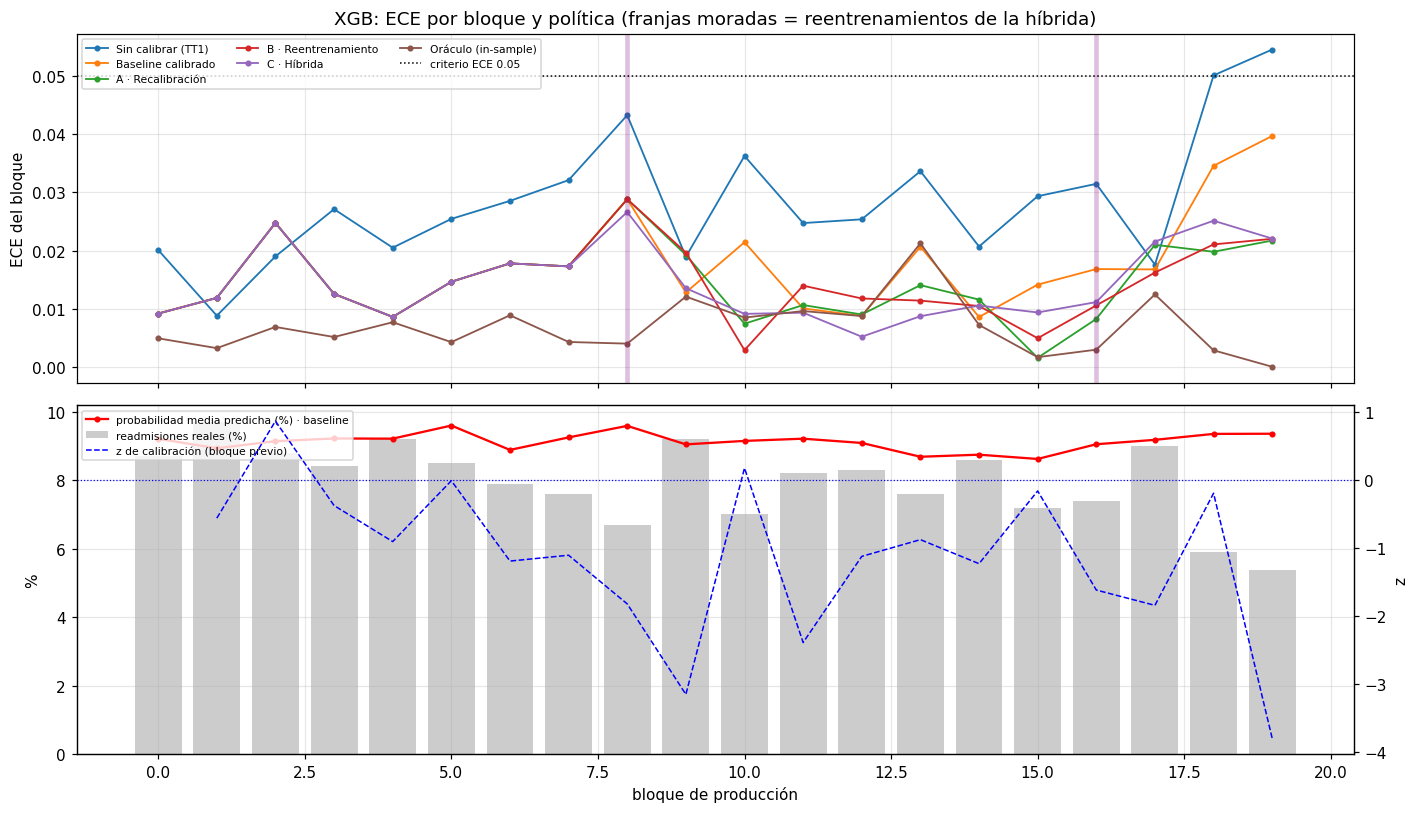

In [30]:
sub = policy_blocks[policy_blocks["modelo"] == BEST_KIND.upper()]
fig, axes = plt.subplots(2, 1, figsize=(13, 7.5), sharex=True)
for pol, g in sub.groupby("política", sort=False):
    axes[0].plot(g["bloque"], g["ECE"], marker=".", lw=1.2, label=pol)
for x in sub[(sub["política"] == "C · Híbrida") & sub["acción"].str.startswith("reentrenamiento")]["bloque"]:
    axes[0].axvline(x, color="purple", alpha=0.25, lw=3)
axes[0].axhline(0.05, color="k", ls=":", lw=1, label="criterio ECE 0.05")
axes[0].set_ylabel("ECE del bloque")
axes[0].set_title(f"{BEST_KIND.upper()}: ECE por bloque y política (franjas moradas = reentrenamientos de la híbrida)")
axes[0].legend(fontsize=7, ncol=3)
base = sub[sub["política"] == "Baseline calibrado"]
axes[1].bar(base["bloque"], 100 * base["prevalencia"], color="#cccccc", label="readmisiones reales (%)")
axes[1].plot(base["bloque"], 100 * base["p_media"], "r.-", label="probabilidad media predicha (%) · baseline")
axes[1].set_ylabel("%")
axes[1].set_xlabel("bloque de producción")
ax2 = axes[1].twinx()
ax2.plot(base["bloque"], base["z_calibracion"], "b--", lw=1, label="z de calibración (bloque previo)")
ax2.axhline(0, color="b", ls=":", lw=0.8)
ax2.set_ylabel("z")
ax2.grid(False)
h1, l1 = axes[1].get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
axes[1].legend(h1 + h2, l1 + l2, fontsize=7, loc="upper left")
plt.tight_layout()
plt.show()

### 4.7 Validación del monitor: falsas alarmas y latencia (criterios del protocolo)
Se construyen escenarios de **verdad conocida** con los datos reales.

**Construcción de los escenarios:**
- Producción se divide al azar en dos mitades.
- Con la primera se "despliega" un sistema calibrado para esa distribución: Platt, referencias y umbrales nulos.
- Con la segunda se generan flujos de 20 bloques de 500 pacientes:
  - **Estacionario:** toda alerta es falsa → tasa de falsas alarmas por bloque.
  - **Label shift inyectado** desde el bloque 11: la tasa de readmisión se multiplica × 1.5, × 2 o × 3.

Criterios del protocolo: falsas alarmas < 15 % y latencia ≤ 500 muestras.

In [31]:
def monitor_validation(kind, R, multipliers, block, n_pre=10, n_post=10, seed=SEED):
    rng = np.random.default_rng(seed)
    model = MODELS[kind]
    perm = rng.permutation(len(idx_pr))
    h_ref, h_str = perm[: len(perm) // 2], perm[len(perm) // 2:]
    s_all = raw_scores(model, X_pr)
    cal_v = PlattScaler().fit(s_all[h_ref], y_pr[h_ref])
    half = len(h_ref) // 2
    oof_v = np.zeros(len(h_ref))
    oof_v[half:] = PlattScaler().fit(s_all[h_ref[:half]], y_pr[h_ref[:half]]).predict(s_all[h_ref[half:]])
    oof_v[:half] = PlattScaler().fit(s_all[h_ref[half:]], y_pr[h_ref[half:]]).predict(s_all[h_ref[:half]])
    z_thr = z_null_thresholds(y_pr[h_ref], oof_v, n=block, B=500, seed=seed)
    f_ref, f_thr = fit_psi_monitor(MON_PR.iloc[h_ref], [block], B=CONFIG["psi_null_B"], seed=seed,
                                   n_bins=CONFIG["psi_bins"], max_categories=CONFIG["psi_max_categories"])
    s_ref, s_thr = score_reference(s_all[h_ref], seed, n=block)
    pos, neg = h_str[y_pr[h_str] == 1], h_str[y_pr[h_str] == 0]
    pi = len(pos) / len(h_str)
    far_rows, lat_rows = [], []
    for m in [1.0] + list(multipliers):
        for _ in range(R):
            prev, first = None, {1: None, 2: None}
            for t in range(n_pre + n_post):
                k = rng.binomial(block, min(pi * (1.0 if t < n_pre else m), 0.95))
                ib = np.concatenate([rng.choice(pos, k, replace=True), rng.choice(neg, block - k, replace=True)])
                sig = compute_signals(MON_PR.iloc[ib], s_all[ib], prev, f_ref, f_thr[block], s_ref, s_thr, z_thr)
                prev = (y_pr[ib], cal_v.predict(s_all[ib]))
                if t < n_pre or m == 1.0:
                    if t >= 1:
                        far_rows.append({k_: sig[k_] for k_ in ["alerta", "nivel_score", "nivel_calibracion", "nivel_variables_info"]})
                else:
                    for lv in (1, 2):
                        if first[lv] is None and sig["alerta"] >= lv:
                            first[lv] = (t - n_pre + 1) * block
            if m != 1.0:
                lat_rows.append({"multiplicador_de_prevalencia": m, "latencia_N1": first[1], "latencia_N2": first[2]})
    far = pd.DataFrame(far_rows)
    far_tbl = pd.DataFrame([{"señal": name, "bloques_sin_drift": len(far), "falsas_alarmas_nivel≥1_%": 100 * (far[col] >= 1).mean(),
                             "falsas_alarmas_nivel2_%": 100 * (far[col] == 2).mean()}
                            for name, col in [("ALERTA DE ACCIÓN (score + calibración)", "alerta"), ("PSI del score", "nivel_score"),
                                              ("z de calibración", "nivel_calibracion"), ("PSI de variables (informativa)", "nivel_variables_info")]])
    lat = pd.DataFrame(lat_rows).astype(float)
    lat_tbl = lat.groupby("multiplicador_de_prevalencia").agg(
        det_N2=("latencia_N2", lambda s: 100 * s.notna().mean()), latencia_mediana_N2=("latencia_N2", "median"),
        det_N1=("latencia_N1", lambda s: 100 * s.notna().mean()), latencia_mediana_N1=("latencia_N1", "median")
    ).rename(columns={"det_N2": "detección_N2_%", "det_N1": "detección_N1_%"})
    return far_tbl, lat_tbl

with timed("validacion_monitor_falsas_alarmas_latencia", modelo=BEST_KIND.upper()):
    far_tbl, lat_tbl = monitor_validation(BEST_KIND, CONFIG["monitor_validation_R"], CONFIG["latency_multipliers"], CONFIG["monitor_block"])
print("Tasa de falsas alarmas por bloque en flujos sin drift:")
display(far_tbl.round(2))
print("Latencia (pacientes observados desde el inicio del cambio hasta la alerta) y tasa de detección en 10 bloques:")
lat_tbl.round(1)

⏱  validacion_monitor_falsas_alarmas_latencia: 13.887 s  (RSS 739 MB)
Tasa de falsas alarmas por bloque en flujos sin drift:


,señal,bloques_sin_drift,falsas_alarmas_nivel≥1_%,falsas_alarmas_nivel2_%
0,ALERTA DE ACCIÓN (score + calibración),920,14.13,5.33
1,PSI del score,920,5.87,1.30
2,z de calibración,920,8.91,4.13
3,PSI de variables (informativa),920,0.54,0.33


Latencia (pacientes observados desde el inicio del cambio hasta la alerta) y tasa de detección en 10 bloques:


,detección_N2_%,latencia_mediana_N2,detección_N1_%,latencia_mediana_N1
multiplicador_de_prevalencia,,,,
1.5,100.0,1000.0,100.0,1000.0
2.0,100.0,1000.0,100.0,1000.0
3.0,100.0,1000.0,100.0,1000.0


**Lectura consolidada (políticas y monitor):** la celda siguiente resume, con los números de esta corrida, el efecto de cada política respecto del baseline calibrado.

In [32]:
ps = policy_summary.set_index(["modelo", "política"])
effect = []
for mdl in ["LR", "XGB"]:
    b0 = ps.loc[(mdl, "Baseline calibrado")]
    for pol in ["A · Recalibración", "B · Reentrenamiento", "C · Híbrida", "Oráculo (in-sample)"]:
        r = ps.loc[(mdl, pol)]
        effect.append({"modelo": mdl, "política": pol, "ΔAUC": r["AUC"] - b0["AUC"], "ΔAP": r["AP"] - b0["AP"], "ΔLogLoss": r["LogLoss"] - b0["LogLoss"],
                       "ΔECE_agregado": r["ECE"] - b0["ECE"], "O/E": r["O/E"], "intervenciones": int(r["recalibraciones"] + r["reentrenamientos"]),
                       "segundos": r["seg_en_intervenciones"]})
effect = pd.DataFrame(effect)
best_by_model = {m: g[~g["política"].str.startswith("Oráculo")].sort_values("ΔLogLoss").iloc[0]["política"] for m, g in effect.groupby("modelo")}
far_row = far_tbl[far_tbl["señal"].str.startswith("ALERTA")].iloc[0]
bk = BEST_KIND.upper()
print(f"Baseline {bk}: O/E = {ps.loc[(bk, 'Baseline calibrado'), 'O/E']:.3f} · bloques con alerta de acción: {ps.loc[(bk, 'Baseline calibrado'), '%bloques_alerta≥1']:.0f} % · "
      f"bloques con PSI de variables en nivel ≥ 1 (informativo): {ps.loc[(bk, 'Baseline calibrado'), '%bloques_PSI_variables≥1']:.0f} %")
print(f"Falsas alarmas en flujos sin drift: nivel 2 = {far_row['falsas_alarmas_nivel2_%']:.1f} % · nivel ≥ 1 = {far_row['falsas_alarmas_nivel≥1_%']:.1f} % (criterio < 15 %)")
print("Latencia mediana N1 (pacientes): " + ", ".join(f"×{k:g} → {v:.0f}" for k, v in lat_tbl["latencia_mediana_N1"].items()))
print("Mejor política activa por log-loss agregada: " + ", ".join(f"{m} → {p}" for m, p in best_by_model.items()))
print("Efecto respecto del baseline calibrado (Δ negativo en LogLoss/ECE = mejora; Δ positivo en AUC/AP = mejora):")
effect.round(4)

Baseline XGB: O/E = 0.874 · bloques con alerta de acción: 30 % · bloques con PSI de variables en nivel ≥ 1 (informativo): 100 %
Falsas alarmas en flujos sin drift: nivel 2 = 5.3 % · nivel ≥ 1 = 14.1 % (criterio < 15 %)
Latencia mediana N1 (pacientes): ×1.5 → 1000, ×2 → 1000, ×3 → 1000
Mejor política activa por log-loss agregada: LR → C · Híbrida, XGB → C · Híbrida
Efecto respecto del baseline calibrado (Δ negativo en LogLoss/ECE = mejora; Δ positivo en AUC/AP = mejora):


,modelo,política,ΔAUC,ΔAP,ΔLogLoss,ΔECE_agregado,O/E,intervenciones,segundos
0,LR,A · Recalibración,0.0007,-0.0001,-0.0013,-0.0074,0.9313,4,0.7382
1,LR,B · Reentrenamiento,-0.0001,0.0001,-0.0013,-0.0086,0.9659,1,1.4982
2,LR,C · Híbrida,0.0031,0.0021,-0.0017,-0.0079,0.9360,6,6.4850
3,LR,Oráculo (in-sample),0.0111,0.0069,-0.0028,-0.0122,1.0001,0,0.0000
4,XGB,A · Recalibración,0.0001,-0.0016,-0.0008,-0.0062,0.9571,3,0.4917
5,XGB,B · Reentrenamiento,-0.0004,-0.0009,-0.0009,-0.0066,0.9597,3,2.5343
6,XGB,C · Híbrida,0.0040,0.0021,-0.0014,-0.0063,0.9442,5,3.1926
7,XGB,Oráculo (in-sample),0.0114,0.0060,-0.0024,-0.0079,1.0001,0,0.0000


**Cómo interpretar estos resultados en la defensa:**
- **El drift de Diabetes combina dos mecanismos:**
  - Cambios de captura en *X*: persistentes, visibles en el PSI de variables.
  - Una tasa de readmisión que baja con el tiempo (label shift): visible en la z de calibración y en O/E < 1.
- Por eso las señales de acción se centran en el score y la calibración. Un monitor basado solo en el PSI de variables (como TT1) estaría encendido permanentemente sin decir si las probabilidades siguen siendo correctas.
- **Las intervenciones corrigen el nivel de riesgo:** la recalibración ajusta el intercepto con las etiquetas maduras más recientes y acerca O/E a 1. El reentrenamiento incorpora además los cambios de captura. La tabla de efectos cuantifica cuál conviene para cada modelo y a qué costo.
- **Latencia:** la señal que detecta el label shift puro es la z de calibración, que necesita etiquetas. Con bloques de 500 y un bloque de retraso (≈ los 30 días que tarda en madurar la etiqueta), la alerta llega tras 1 000 pacientes, por encima del criterio de 500. La latencia está acotada por la madurez de la etiqueta, no por el monitor.
- **La mejora frente a TT1 no depende solo de las políticas.** La corrección más grande es eliminar la miscalibración autoinducida por los pesos de clase (§3.6) y evaluar sin etiquetas censuradas (§1.7).
- Las cifras exactas pueden variar ligeramente con el número de CPUs de Colab.

### 4.8 Comparación TT1 vs TT2
Las cifras de TT1 provienen del notebook entregado en TT1.

**Diferencias de esquema:**
- TT1 promedió métricas en ventanas de 500 encuentros (paso 200).
- TT2 reporta métricas agregadas y, para comparar en igualdad de condiciones, también las **mismas ventanas** aplicadas a sus predicciones.
- La producción de TT2 excluye la cola censurada. La de TT1 la incluía, lo que favorece a TT1 en tamaño de muestra pero lo perjudica en calidad de etiqueta.

In [33]:
def tt1_window_metrics(idx_issued, p_issued):
    order = np.argsort(idx_issued)
    ii, pp = idx_issued[order], p_issued[order]
    yy = y_all[ii]
    W, S = CONFIG["tt1_window"], CONFIG["tt1_stride"]
    vals = [(ece_uniform(yy[s:s + W], pp[s:s + W]), np.mean((pp[s:s + W] - yy[s:s + W]) ** 2),
             roc_auc_score(yy[s:s + W], pp[s:s + W]) if 0 < yy[s:s + W].mean() < 1 else np.nan) for s in range(0, len(yy) - W + 1, S)]
    return np.nanmean(np.array(vals), axis=0)

xgb_active = policy_summary[(policy_summary["modelo"] == "XGB") & policy_summary["política"].isin(["A · Recalibración", "B · Reentrenamiento", "C · Híbrida"])]
best_pol_xgb = xgb_active.set_index("política")["LogLoss"].idxmin()
rows = [
    {"comparación": "LR · split de calibración · AUC (sin calibrar)", "TT1": 0.6265, "TT2": roc_auc_score(y_ca, raw_cal["lr"])},
    {"comparación": "LR · split de calibración · AP (sin calibrar)", "TT1": 0.1401, "TT2": average_precision_score(y_ca, raw_cal["lr"])},
    {"comparación": "LR · split de calibración · ECE (sin calibrar)", "TT1": 0.3967, "TT2": ece_uniform(y_ca, raw_cal["lr"])},
    {"comparación": "XGB · split de calibración · AUC (sin calibrar)", "TT1": 0.6219, "TT2": roc_auc_score(y_ca, raw_cal["xgb"])},
    {"comparación": "XGB · split de calibración · AP (sin calibrar)", "TT1": 0.1530, "TT2": average_precision_score(y_ca, raw_cal["xgb"])},
    {"comparación": "XGB · split de calibración · ECE (sin calibrar)", "TT1": 0.3332, "TT2": ece_uniform(y_ca, raw_cal["xgb"])},
]
for label, pol, tt1_vals in [("Baseline", "Baseline calibrado", (0.3549, 0.2077, 0.6231, 0)),
                             ("Mejor política activa", best_pol_xgb, (0.1930, 0.1292, np.nan, 103))]:
    e, b, a = tt1_window_metrics(*ISSUED[("xgb", pol)])
    r = policy_summary.set_index(["modelo", "política"]).loc[("XGB", pol)]
    rows += [{"comparación": f"XGB · producción · {label} · ECE medio en ventanas de 500", "TT1": tt1_vals[0], "TT2": e},
             {"comparación": f"XGB · producción · {label} · Brier medio en ventanas de 500", "TT1": tt1_vals[1], "TT2": b},
             {"comparación": f"XGB · producción · {label} · ECE agregado", "TT1": np.nan, "TT2": r["ECE"]},
             {"comparación": f"XGB · producción · {label} · intervenciones", "TT1": tt1_vals[3], "TT2": r["recalibraciones"] + r["reentrenamientos"]}]
    if label == "Baseline":
        rows.append({"comparación": "XGB · producción · Baseline · AUC medio en ventanas de 500", "TT1": tt1_vals[2], "TT2": a})
comparison = pd.DataFrame(rows)
print(f"Mejor política activa TT2 (XGB, menor log-loss agregada): {best_pol_xgb}")
print(f"Referencia: predecir siempre la tasa base daría Brier ≈ {y_pr.mean() * (1 - y_pr.mean()):.3f}. Los Brier de TT1 (0.13–0.21) eran peores que ese "
      "predictor constante por la miscalibración inducida por los pesos de clase.")
comparison.round(4)

Mejor política activa TT2 (XGB, menor log-loss agregada): C · Híbrida
Referencia: predecir siempre la tasa base daría Brier ≈ 0.073. Los Brier de TT1 (0.13–0.21) eran peores que ese predictor constante por la miscalibración inducida por los pesos de clase.


,comparación,TT1,TT2
0,LR · split de calibración · AUC (sin calibrar),0.6265,0.6493
1,LR · split de calibración · AP (sin calibrar),0.1401,0.1580
2,LR · split de calibración · ECE (sin calibrar),0.3967,0.0151
3,XGB · split de calibración · AUC (sin calibrar),0.6219,0.6557
4,XGB · split de calibración · AP (sin calibrar),0.1530,0.1726
5,XGB · split de calibración · ECE (sin calibrar),0.3332,0.0177
6,XGB · producción · Baseline · ECE medio en ven...,0.3549,0.0204
7,XGB · producción · Baseline · Brier medio en v...,0.2077,0.0725
8,XGB · producción · Baseline · ECE agregado,NaN,0.0115
9,XGB · producción · Baseline · intervenciones,0.0000,0.0000


## 5. Preparación para el dashboard (pipeline de inferencia)
### 5.1 Empaquetado del modelo y exportación de artefactos
**`bundle.joblib`** es un único objeto que el dashboard carga. Contiene:
- Los dos `ReadmissionScorer`: modelo + `DiabetesFeaturizer` (con `IDS_mapping` y vocabularios) + calibrador + umbral + bandas.
- El modelo recomendado.
- La referencia PSI y sus umbrales nulos.
- El diccionario de variables.

**Otros archivos:**
- XGBoost también se guarda en formato nativo `.json`.
- Se copian `diabetes_tt2.py` y la tabla ordenada de `IDS_mapping`.
- `metadata.json` documenta la corrida.
- Cada tabla del análisis se exporta en parquet o CSV.

In [34]:
scorers = {k: ReadmissionScorer(name=f"{k.upper()} + {CAL_METHOD[k]}", kind=k, model=MODELS[k], calibrator=CALIBRATOR[k],
                               featurizer=featurizer, threshold=THRESHOLDS[k], risk_cuts=CONFIG["risk_cuts"]) for k in MODELS}
bundle = {"schema_version": "1.0", "run_id": RUN_ID, "created_utc": dt.datetime.now(dt.timezone.utc).isoformat(),
          "dataset": "Diabetes 130-US Hospitals 1999–2008 (UCI 296)", "scorers": scorers, "best": BEST_KIND,
          "psi_reference": psi_train_ref, "psi_null": {int(n): {"p95": v["p95"], "p99": v["p99"]} for n, v in null_thr.items()},
          "feature_labels": FEATURE_LABELS, "model_features": MODEL_FEATURES, "raw_input": RAW_INPUT, "ids_mapping": IDS}

def _cal_params(c):
    return {a.rstrip("_"): float(getattr(c, a)) for a in ("T_", "a_", "b_") if hasattr(c, a)}

metadata = {
    "schema_version": "1.0", "run_id": RUN_ID, "proyecto": "TT 2026-B080 · Detección y Mitigación de Calibration Drift",
    "dataset": "Diabetes 130-US Hospitals 1999–2008 (UCI 296)", "sha256_datos": DATA_HASHES, "entorno": ENV, "config": CONFIG,
    "cohorte": cohort_steps.to_dict(orient="records"), "periodos_censurados_excluidos": CENSORED_PERIODS,
    "altas_excluidas": EXCLUDED_DISCHARGE,
    "particion": {s: {"encuentros": int(len(y)), "tasa_readmision_30d": float(y.mean())} for s, y in [("train", y_tr), ("calibration", y_ca), ("production", y_pr)]},
    "modelos": {k: {"calibrador": CAL_METHOD[k], "parametros_calibrador": _cal_params(CALIBRATOR[k]), "umbral_F2": THRESHOLDS[k]} for k in MODELS},
    "xgb_n_arboles": best_iter, "lr_C": best_C, "modelo_recomendado": BEST_KIND,
    "metricas_produccion_modelo_recomendado": metrics_production.set_index("modelo").loc[BEST_LABEL].to_dict(),
    "bandas_riesgo": {"Bajo": f"< {CONFIG['risk_cuts'][0]}", "Medio": f"{CONFIG['risk_cuts'][0]}–{CONFIG['risk_cuts'][1]}", "Alto": f"≥ {CONFIG['risk_cuts'][1]}"},
}
tables = {"entorno": pd.DataFrame([ENV]), "faltantes_crudos": profile.reset_index(names="columna"), "ids_mapping": IDS,
          "ids_mapping_tt1_vs_tt2": cmp_ids, "cohorte": cohort_steps, "periodos": by_period.reset_index(), "validacion_dataset": validation,
          "particion": split_summary.reset_index(), "faltantes_train_vs_produccion": miss_cmp.reset_index(names="columna"), "dimensionalidad": dims,
          "psi_periodos": psi_periods.reset_index(names="variable").rename(columns=str), "psi_splits": psi_splits.reset_index(names="variable"),
          "psi_umbrales_nulos": psi_null, "seleccion_C_lr": lr_search, "tiempos_protocolo": timing_protocol, "ablaciones": ablation,
          "benchmark": benchmark, "seleccion_calibrador": calib_sel, "metricas_produccion": metrics_production,
          "confiabilidad_bins": reliability_bins, "piso_ruido_ece": noise_floor, "bandas_riesgo": band_tbl.reset_index().astype({"banda": str}),
          "politicas_bloques": policy_blocks, "politicas_resumen": policy_summary, "politicas_efecto": effect,
          "monitor_falsas_alarmas": far_tbl, "monitor_latencia": lat_tbl.reset_index(), "tt1_vs_tt2": comparison}
with timed("exportacion_artefactos"):
    joblib.dump(bundle, ART / "bundle.joblib", compress=3)
    xgb_model.save_model(ART / "xgb_model.json")
    shutil.copy("src/diabetes_tt2.py", ART / "diabetes_tt2.py")
    saved = {name: save_table(df, name).name for name, df in tables.items() if isinstance(df, pd.DataFrame) and len(df)}
    metadata["artefactos"] = ["bundle.joblib", "xgb_model.json", "diabetes_tt2.py", "metadata.json", *saved.values()]
    (ART / "metadata.json").write_text(json.dumps(metadata, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
print(f"Artefactos en {ART.resolve()} · bundle.joblib = {(ART / 'bundle.joblib').stat().st_size / 1e3:,.0f} KB")
pd.DataFrame({"archivo": sorted(p.name for p in ART.iterdir())})

⏱  exportacion_artefactos: 0.180 s  (RSS 746 MB)
Artefactos en /content/artifacts/diabetes/tt2_diabetes_20261018T143240Z · bundle.joblib = 37 KB


,archivo
0,ablaciones.parquet
1,bandas_riesgo.parquet
2,benchmark.parquet
3,bundle.joblib
4,cohorte.parquet
5,confiabilidad_bins.parquet
6,diabetes_tt2.py
7,dimensionalidad.parquet
8,entorno.parquet
9,faltantes_crudos.parquet


### 5.2 Función de inferencia `predict_readmission(nuevos_encuentros)`
Simula cómo el dashboard consumirá el modelo:
1. Carga el bundle **desde disco**, con caché.
2. Acepta un `dict` (formulario de alta), una lista de dicts o un `DataFrame` con las columnas originales de `diabetic_data.csv`. Los IDs administrativos y los códigos ICD-9 van tal cual; el modelo los traduce con `IDS_mapping`.
3. Tolera columnas ausentes: se tratan como desconocidas, o "No" en el caso de medicamentos.
4. Devuelve por paciente:
   - Probabilidad calibrada de readmisión < 30 días.
   - Banda de riesgo.
   - Alerta según el umbral F2.
   - Los factores que más empujan la predicción.
5. Con lotes de ≥ 200 pacientes añade un reporte de drift en `.attrs["drift"]`.

In [35]:
_BUNDLES = {}

def load_bundle(path=ART / "bundle.joblib"):
    path = Path(path).resolve()
    if path not in _BUNDLES:
        _BUNDLES[path] = joblib.load(path)
    return _BUNDLES[path]

def predict_readmission(nuevos_encuentros, modelo="best", bundle_path=ART / "bundle.joblib", explicar=True, top_k=3, verificar_drift=True):
    """Probabilidad calibrada de readmisión < 30 días para el dashboard.

    nuevos_encuentros : dict | list[dict] | pandas.DataFrame con columnas de diabetic_data.csv
    modelo            : "best" (recomendado), "xgb" o "lr"
    Devuelve un DataFrame con prob_readmision_30d, banda_riesgo, alerta y factores_principales;
    en .attrs["drift"] el reporte de drift del lote (≥ 200 filas) y en .attrs["modelo"] el modelo usado.
    """
    if isinstance(nuevos_encuentros, dict):
        df = pd.DataFrame([nuevos_encuentros])
    elif isinstance(nuevos_encuentros, (list, tuple)):
        df = pd.DataFrame(list(nuevos_encuentros))
    elif isinstance(nuevos_encuentros, pd.DataFrame):
        df = nuevos_encuentros.copy()
    else:
        raise TypeError("nuevos_encuentros debe ser dict, lista de dicts o DataFrame")
    res = diabetes_tt2.score_batch(load_bundle(bundle_path), df, model=modelo, explain=explicar, top_k=top_k, drift_check=verificar_drift)
    for w in res["advertencias"]:
        print("⚠️ ", w)
    out = res["predicciones"]
    out.attrs["modelo"], out.attrs["drift"] = res["modelo"], res["drift"]
    return out

### 5.3 Prueba de consumo (simulación del dashboard)
Se verifica:
1. **Consistencia:** el bundle cargado desde disco reproduce las probabilidades del notebook.
2. **Formulario de alta parcial:** faltan medicamentos y hay un código de destino al alta inexistente.
3. **Lote** de 1 000 pacientes con verificación de drift.

In [36]:
with timed("prueba_inferencia_dashboard"):
    _BUNDLES.clear()
    muestra = cohort.loc[idx_pr[:5], [c for c in RAW_INPUT if c in cohort.columns]]
    pred = predict_readmission(muestra)
p_nb = CALIBRATOR[BEST_KIND].predict(raw_scores(MODELS[BEST_KIND], X_all.loc[idx_pr[:5]]))
print(f"Modelo usado: {pred.attrs['modelo']} · consistencia bundle (disco) ↔ notebook: {np.allclose(pred['prob_readmision_30d'].to_numpy(), p_nb)}")
display(pred.assign(real=cohort.loc[idx_pr[:5], "y"].to_numpy()))

print("\nFormulario de alta parcial:")
formulario = {"race": "Caucasian", "gender": "Female", "age": "[70-80)", "admission_type_id": 1, "discharge_disposition_id": 99,
              "admission_source_id": 7, "time_in_hospital": 6, "medical_specialty": "InternalMedicine", "num_lab_procedures": 55,
              "num_procedures": 1, "num_medications": 18, "number_outpatient": 0, "number_emergency": 1, "number_inpatient": 2,
              "diag_1": "428", "diag_2": "250.02", "diag_3": "401", "number_diagnoses": 9, "A1Cresult": ">8", "insulin": "Up",
              "change": "Ch", "diabetesMed": "Yes"}
display(predict_readmission(formulario, verificar_drift=False))

with timed("inferencia_lote_1000_con_drift"):
    lote = predict_readmission(cohort.loc[idx_pr[-1000:]], explicar=False)
print("Reporte de drift del lote (últimos 1 000 pacientes de producción):")
print(json.dumps(lote.attrs["drift"], ensure_ascii=False, indent=1))
lote["banda_riesgo"].value_counts()

⚠️  Verificación de drift omitida: se requieren ≥ 200 filas
⏱  prueba_inferencia_dashboard: 0.110 s  (RSS 765 MB)
Modelo usado: xgb · consistencia bundle (disco) ↔ notebook: True


,prob_readmision_30d,banda_riesgo,alerta,factores_principales,real
46540,0.043475,Bajo,0,discharge_disposition ↓ (Destino al alta); dia...,0
46541,0.118363,Medio,1,discharge_disposition ↑ (Destino al alta); med...,1
46542,0.080642,Medio,1,number_inpatient ↑ (Hospitalizaciones en el añ...,1
46543,0.175396,Alto,1,discharge_disposition ↑ (Destino al alta); pri...,0
46544,0.049862,Bajo,0,discharge_disposition ↓ (Destino al alta); dia...,0



Formulario de alta parcial:
⚠️  23 columna(s) ausente(s) → se tratan como desconocidas/No: ['max_glu_serum', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide']
⚠️  1 fila(s) con discharge_disposition_id fuera de IDS_mapping → 'Desconocido'


,prob_readmision_30d,banda_riesgo,alerta,factores_principales
0,0.176369,Alto,1,number_inpatient ↑ (Hospitalizaciones en el añ...


⏱  inferencia_lote_1000_con_drift: 0.105 s  (RSS 765 MB)
Reporte de drift del lote (últimos 1 000 pacientes de producción):
{
 "n": 1000,
 "psi_max": 0.9554601538710257,
 "nivel": 2,
 "umbral_p95": 0.035834768106433317,
 "umbral_p99": 0.04326885598623628,
 "n_referencia_umbral": 1000,
 "top_variables": {
  "payer_code": 0.9555,
  "medical_specialty": 0.6262,
  "discharge_disposition": 0.5913,
  "number_diagnoses": 0.5319,
  "admission_source": 0.3583,
  "admission_type": 0.2781
 }
}


,count
banda_riesgo,
Bajo,540
Medio,341
Alto,119


### 5.4 Contrato de artefactos → vistas del dashboard (observación 5)
El maquetado visual es un entregable aparte. Esta tabla fija **qué datos alimentan cada vista**; el frontend solo lee artefactos versionados por `run_id`.

| Vista del dashboard | Artefactos |
|---|---|
| P1 · Resumen ejecutivo (semáforo vs criterios del protocolo) | `metadata.json`, `metricas_produccion`, `politicas_resumen`, `monitor_falsas_alarmas`, `monitor_latencia` |
| P2 · Dataset (ficha llana, cohorte, validador, IDS_mapping) | `cohorte`, `periodos`, `validacion_dataset`, `ids_mapping`, `ids_mapping_tt1_vs_tt2`, `faltantes_crudos`, `faltantes_train_vs_produccion`, `dimensionalidad` |
| P3 · Monitor temporal (señales y alertas) | `politicas_bloques` (señales, niveles, acciones), `psi_periodos`, `psi_splits`, `psi_umbrales_nulos` |
| P4 · Comparación de políticas (tabla, curvas, costo) | `politicas_resumen`, `politicas_efecto`, `politicas_bloques`, `tt1_vs_tt2` |
| P5 · Calibración (confiabilidad, piso de ruido, bandas) | `confiabilidad_bins`, `seleccion_calibrador`, `piso_ruido_ece`, `bandas_riesgo` |
| P6 · Predicción interactiva (*what-if* por paciente) | `bundle.joblib` + `diabetes_tt2.py` → `diabetes_tt2.score_batch()` |
| P7 · Rendimiento computacional | `tiempos_protocolo`, `tiempos_etapas`, `entorno` |
| P8 · Reproducibilidad | `metadata.json` (config, semillas, versiones, SHA-256 de datos, cohorte) |

Consumo mínimo desde el dashboard:
```python
import sys, joblib; sys.path.insert(0, "<carpeta_de_artefactos>")
import diabetes_tt2
bundle = joblib.load("<carpeta_de_artefactos>/bundle.joblib")
resultado = diabetes_tt2.score_batch(bundle, df_altas)
```

### 5.5 Resumen de tiempos de procesamiento y empaquetado final (observación 1)

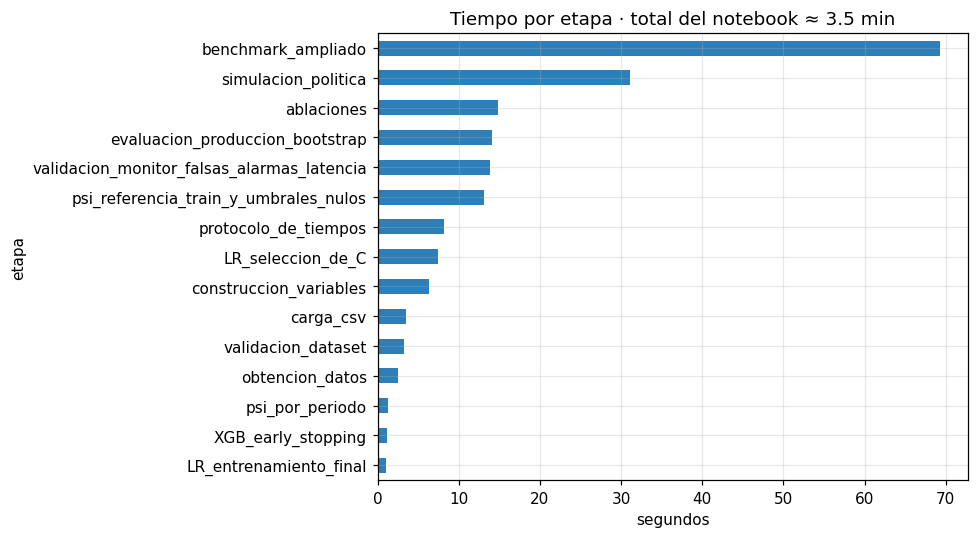

Tiempo total de ejecución: 210.2 s en 2 CPU lógicos. RNF-03 (≤ 90 min para los tres datasets ≈ 30 min por dataset): ✅ cumple
Paquete de artefactos: /content/artifacts/diabetes/tt2_diabetes_20261018T143240Z.zip


,segundos
etapa,
benchmark_ampliado,69.281
simulacion_politica,31.159
ablaciones,14.813
evaluacion_produccion_bootstrap,14.097
validacion_monitor_falsas_alarmas_latencia,13.887
psi_referencia_train_y_umbrales_nulos,13.140
protocolo_de_tiempos,8.171
LR_seleccion_de_C,7.387
construccion_variables,6.307


In [37]:
timings_df = pd.DataFrame(TIMINGS)
save_table(timings_df, "tiempos_etapas")
total = time.perf_counter() - NOTEBOOK_T0
agg = timings_df.groupby("etapa", sort=False)["segundos"].sum().sort_values(ascending=False)
ax = agg.head(15).iloc[::-1].plot(kind="barh", figsize=(9, 5), color="#2c7fb8",
                                    title=f"Tiempo por etapa · total del notebook ≈ {total / 60:.1f} min")
ax.set_xlabel("segundos")
plt.tight_layout()
plt.show()
print(f"Tiempo total de ejecución: {total:,.1f} s en {ENV['cpus_logicos']} CPU lógicos. "
      f"RNF-03 (≤ 90 min para los tres datasets ≈ 30 min por dataset): {'✅ cumple' if total < 30 * 60 else '⚠️ revisar'}")
zip_path = shutil.make_archive(str(ART), "zip", ART)
print(f"Paquete de artefactos: {zip_path}")
if IN_COLAB and CONFIG["download_artifacts"]:
    from google.colab import files
    files.download(zip_path)
agg.round(3).to_frame("segundos")

### Cierre: observaciones del jurado resueltas en este notebook
| # | Observación | Evidencia en el notebook |
|---|---|---|
| 1 | Tiempos de procesamiento | `%%time` en entrenamientos; `TIMINGS` por etapa con memoria; protocolo con repeticiones y hardware (§3.5); costo en segundos de cada intervención (§4.6); resumen (§5.5). |
| 2 | Justificación de modelos | Argumentación técnica con enfoque clínico (§3.1); ablaciones de pesos, IDS_mapping, medicamentos y captura (§3.6); benchmark de 5 candidatos (§3.7). |
| 3 | Explicación sin tecnicismos | Ficha en lenguaje llano (§1.5) y tabla de transformaciones (§2.3), reutilizables en la vista P2. |
| 4 | Requisitos de dataset candidato | `validate_dataset()` con 12 requisitos, incluidos independencia de filas y madurez de la etiqueta (§1.8). |
| 5 | Maquetado del dashboard | Contrato de artefactos por vista y `predict_readmission()` probada con formularios parciales y lotes (§5.1–5.4). |
| 6 | Estático vs ajuste de dimensionalidad | Esquema congelado por versión; reducción guiada por dominio: 148 → ~27 variables, interpretables (§2.5, §3.6). |